# Predictions Test Analysis

Analysis of model predictions on the NIST23 test set (9-fold cross-validation), joining:
- `data/predicted/nps_inchikey_nist23_nist23_cv{0..8}.zip` — model outputs and cosine similarity scores (one zip per CV fold)
- `data/proc/nist23/spec_df.pkl` — spectrum metadata
- `data/proc/nist23/mol_df.pkl` — molecule metadata
- `data/classyfire/nist23_mol_classyfire.pkl` — ClassyFire chemical taxonomy labels

All 9 CV folds are concatenated into a single DataFrame before analysis.

In [1]:
import gc
import pickle
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 11,
})

DATA_ROOT = Path("../data")

## 1. Load Data

In [2]:
# Load and combine predictions from all 9 CV folds
cv_dfs = []
for cv_idx in range(9):
    zip_path = DATA_ROOT / f"predicted/nps_inchikey_nist23_nist23_cv{cv_idx}.zip"
    with zipfile.ZipFile(zip_path) as zf:
        pkl_name = next(n for n in zf.namelist() if n.endswith("predictions_test.pkl"))
        with zf.open(pkl_name) as f:
            cv_df = pickle.load(f)
    cv_df["cv_fold"] = cv_idx
    cv_dfs.append(cv_df)
    print(f"  cv{cv_idx}: {len(cv_df):,} rows")

pred_df = pd.concat(cv_dfs, ignore_index=True)
print(f"\nCombined pred_df: {pred_df.shape}  ({pred_df['spec_id'].nunique():,} unique spec_ids)")

with open(DATA_ROOT / "proc/nist23/spec_df.pkl", "rb") as f:
    spec_df = pickle.load(f)

with open(DATA_ROOT / "proc/nist23/mol_df.pkl", "rb") as f:
    mol_df = pickle.load(f)
mol_df = mol_df.drop(columns=["mol"], errors="ignore")

with open(DATA_ROOT / "classyfire/nist23_mol_classyfire.pkl", "rb") as f:
    cf_df = pickle.load(f)

print(f"spec_df:  {spec_df.shape}")
print(f"mol_df:   {mol_df.shape}")
print(f"cf_df:    {cf_df.shape}")

del cv_dfs
gc.collect()


  cv0: 85,660 rows
  cv1: 83,574 rows
  cv2: 85,237 rows
  cv3: 85,873 rows
  cv4: 84,535 rows
  cv5: 84,931 rows
  cv6: 85,025 rows
  cv7: 85,048 rows
  cv8: 84,754 rows

Combined pred_df: (764637, 11)  (527,138 unique spec_ids)
spec_df:  (1899597, 22)
mol_df:   (52787, 13)
cf_df:    (52787, 10)


0

In [3]:
pred_df.head(3)

,spec_id,mol_id,pred_mzs,pred_ints,pred_oos_prob,frag_formula_peak_idxs,frag_formula_peak_mzs,index_rebased,cos_sim_0.01,cos_hun,cv_fold
0,418,34523,"[220.0635986328125, 186.10256958007812, 222.07...","[1.2268697023391724, 4.8837103843688965, 999.9...",0.020965,"[30, 36, 38, 58, 407, 411]","[220.0635986328125, 186.10256958007812, 222.07...",True,0.999276,0.999276,0
1,419,34523,"[194.06053161621094, 173.09475708007812, 220.0...","[1.18855881690979, 4.235246658325195, 2.647926...",0.027789,"[1, 4, 30, 32, 36, 38, 40, 58, 147, 315, 407, ...","[194.06053161621094, 173.09475708007812, 220.0...",True,0.986549,0.986549,0
2,420,34523,"[194.06053161621094, 173.09475708007812, 174.1...","[1.0735852718353271, 13.810319900512695, 2.423...",0.031115,"[1, 4, 8, 28, 30, 32, 36, 38, 40, 58, 147, 315...","[194.06053161621094, 173.09475708007812, 174.1...",True,0.877749,0.877749,0


In [4]:
spec_df.head(3)

,spec_id,mol_id,prec_type,inst_type,frag_mode,spec_type,ion_mode,dset,dset_spec_id,col_gas,...,nce,prec_mz,peaks,ri,group_id,ace_extra_1,nce_extra_1,ace_extra_2,nce_extra_2,ce_type
0,0,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461655,N2,...,44.0,132.0768,"[(53.0135, 2.4), (55.018, 55.2), (55.0292, 4.2...",NaN,0,NaN,NaN,NaN,NaN,single
1,1,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461656,N2,...,54.0,132.0768,"[(53.0135, 5.6), (55.018, 82.6), (55.0293, 7.1...",NaN,0,NaN,NaN,NaN,NaN,single
2,2,8061,[M+H]+,FT,HCD,MS2,P,nist23_hr1,3461657,N2,...,65.0,132.0768,"[(51.0231, 8.7), (53.0136, 12.1), (55.018, 107...",NaN,0,NaN,NaN,NaN,NaN,single


In [5]:
mol_df.head(3)

,smiles,mol_id,inchikey_s,scaffold,formula,inchi,mw,exact_mw,num_atoms,num_bonds,charge,single_mol,num_radicals
0,*C1(C)C(OC2OC(CO)C(O)C(OC3OC(CO)C(O)C(O)C3O)C2...,0,,O=C(OC1CCCCO1)C12CCCCC1C1=CCC3C4CCC(OC5CC(OC6C...,C47H75*O19,,944.098,943.490255,67,74,0,True,0
1,BrC(Br)(Br)c1cnc2ccccc2n1,1,VCCOPRMZNNMFLI,c1ccc2nccnc2c1,C9H5Br3N2,"InChI=1S/C9H5Br3N2/c10-9(11,12)8-5-13-6-3-1-2-...",380.865,377.800284,14,15,0,True,0
2,BrC1=CCCN(Cc2ccccc2)C1,2,OFHMQSKRHZDSQE,C1=CCN(Cc2ccccc2)CC1,C12H14BrN,InChI=1S/C12H14BrN/c13-12-7-4-8-14(10-12)9-11-...,252.155,251.030962,14,15,0,True,0


## 2. Merge DataFrames

In [ ]:
# Load and combine predictions from all 9 CV folds
cv_dfs = []
for cv_idx in range(9):
    zip_path = DATA_ROOT / f"predicted/nps_inchikey_nist23_nist23_cv{cv_idx}.zip"
    with zipfile.ZipFile(zip_path) as zf:
        pkl_name = next(n for n in zf.namelist() if n.endswith("predictions_test.pkl"))
        with zf.open(pkl_name) as f:
            cv_df = pickle.load(f)
    cv_df["cv_fold"] = cv_idx
    cv_dfs.append(cv_df)
    print(f"  cv{cv_idx}: {len(cv_df):,} rows")

pred_df = pd.concat(cv_dfs, ignore_index=True)
print(f"\nCombined pred_df: {pred_df.shape}  ({pred_df['spec_id'].nunique():,} unique spec_ids)")

with open(DATA_ROOT / "proc/nist23/spec_df.pkl", "rb") as f:
    spec_df = pickle.load(f)

with open(DATA_ROOT / "proc/nist23/mol_df.pkl", "rb") as f:
    mol_df = pickle.load(f)
mol_df = mol_df.drop(columns=["mol"], errors="ignore")

with open(DATA_ROOT / "classyfire/nist23_mol_classyfire.pkl", "rb") as f:
    cf_df = pickle.load(f)

print(f"spec_df:  {spec_df.shape}")
print(f"mol_df:   {mol_df.shape}")
print(f"cf_df:    {cf_df.shape}")

# Make Hungarian cosine the default: copy `cos_hun` into the `cos_sim_0.01` column
# so downstream cells referencing `cos_sim_0.01` will effectively use `cos_hun`.
df = pred_df.merge(spec_df[spec_meta_cols], on=["spec_id", "mol_id"], how="left")
# Note: we will perform the rest of the merges below; ensure the column copy happens after
# the final merged `df` is available.

# Merge with molecule metadata
mol_meta_cols = ["mol_id", "smiles", "formula", "mw", "exact_mw", "num_atoms", "num_bonds", "inchikey_s"]
df = df.merge(mol_df[mol_meta_cols], on="mol_id", how="left")

# Merge with ClassyFire labels
cf_meta_cols = ["mol_id", "superklass", "klass", "subklass", "direct_parent"]
df = df.merge(cf_df[cf_meta_cols], on="mol_id", how="left")

# Remove MoNA spectra (adduct-matching artifact skews wrecall to ~0)
df = df[df["dset"] != "mona23"].copy()

print(f"Merged df (NIST23 only): {df.shape}")
df.head(3)

# Ensure `cos_sim_0.01` uses Hungarian cosine by default
if "cos_hun" in df.columns:
    df["cos_sim_0.01"] = df["cos_hun"]

# Clean up
del pred_df, spec_df, mol_df, cf_df
gc.collect()


Merged df (NIST23 only): (698676, 30)


0

## 3. Overall Similarity Score Distribution

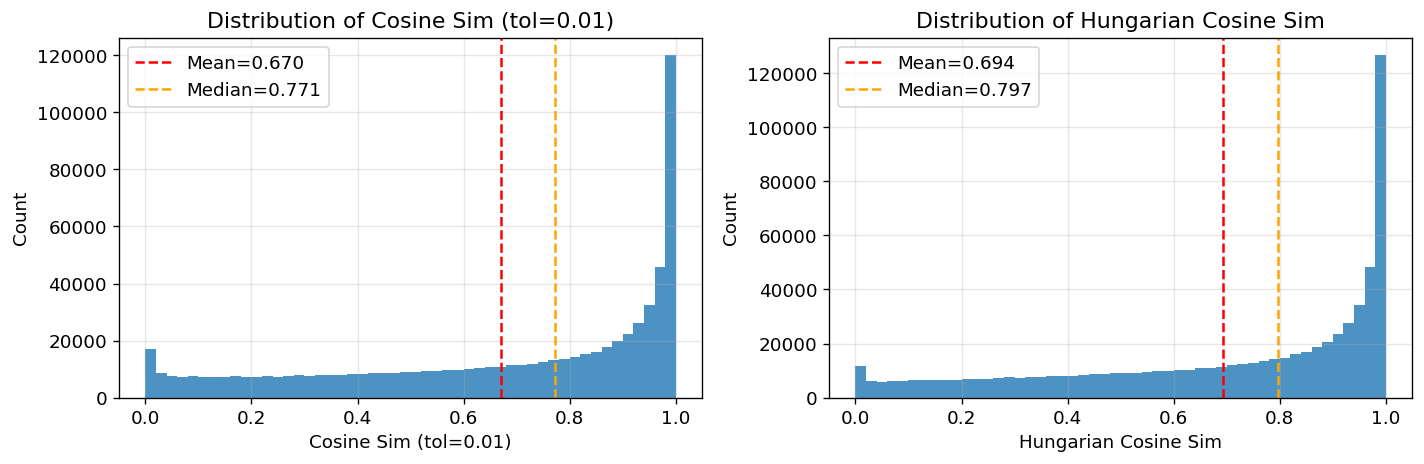

       cos_sim_0.01      cos_hun
count   698676.0000  698676.0000
mean         0.6704       0.6939
std          0.3128       0.2993
min          0.0000       0.0000
25%          0.4295       0.4770
50%          0.7714       0.7972
75%          0.9552       0.9602
max          1.0000       1.0000


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, col, label in zip(
    axes,
    ["cos_sim_0.01", "cos_hun"],
    ["Cosine Sim (tol=0.01)", "Hungarian Cosine Sim"],
):
    ax.hist(df[col], bins=50, edgecolor="none", alpha=0.8)
    ax.axvline(df[col].mean(), color="red", linestyle="--", label=f"Mean={df[col].mean():.3f}")
    ax.axvline(df[col].median(), color="orange", linestyle="--", label=f"Median={df[col].median():.3f}")
    ax.set_xlabel(label)
    ax.set_ylabel("Count")
    ax.set_title(f"Distribution of {label}")
    ax.legend()

plt.tight_layout()
plt.show()

print(df[["cos_sim_0.01", "cos_hun"]].describe().round(4))

## 4. Performance by Instrument Type

In [8]:
inst_stats = (
    df.groupby("inst_type")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
inst_stats

cos_sim_0.01                 cos_hun                
                  mean  median   count    mean  median   count
inst_type                                                     
FT              0.6749  0.7758  678867  0.7011  0.8031  678867
QTOF            0.5178  0.5566   19809  0.4472  0.4079   19809

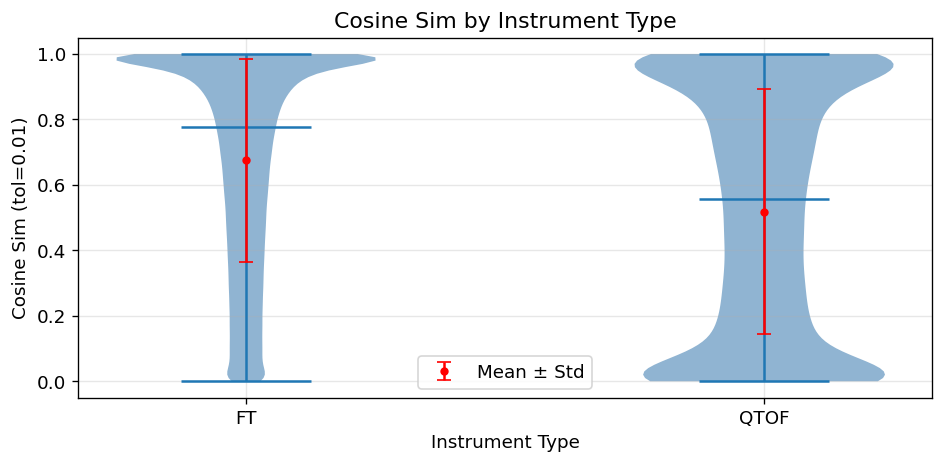

In [9]:
inst_order = df.groupby("inst_type")["cos_sim_0.01"].median().sort_values(ascending=False).index.tolist()
groups = [df.loc[df["inst_type"] == g, "cos_sim_0.01"].dropna().values for g in inst_order]

fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(1, len(groups) + 1)
vp = ax.violinplot(groups, positions=x, showmedians=True, showextrema=True)
for body in vp["bodies"]:
    body.set_facecolor("steelblue")
    body.set_alpha(0.6)
means = [g.mean() for g in groups]
stds = [g.std() for g in groups]
ax.errorbar(x, means, yerr=stds, fmt="o", color="red", capsize=4, markersize=4,
            label="Mean ± Std", zorder=5)
ax.set_xticks(x)
ax.set_xticklabels(inst_order)
ax.set_title("Cosine Sim by Instrument Type")
ax.set_xlabel("Instrument Type")
ax.set_ylabel("Cosine Sim (tol=0.01)")
ax.legend()
plt.tight_layout()
plt.show()

## 5. Performance by Precursor Type

In [10]:
top_prec_types = df["prec_type"].value_counts().head(8).index
df_top = df[df["prec_type"].isin(top_prec_types)]

prec_stats = (
    df_top.groupby("prec_type")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
prec_stats

cos_sim_0.01                 cos_hun                
                  mean  median   count    mean  median   count
prec_type                                                     
[M+Cl]-         0.5704  0.6266    9086  0.6134  0.6981    9086
[M+H]+          0.6807  0.7752  475007  0.7006  0.7975  475007
[M+Na]+         0.6400  0.7624   52730  0.6708  0.7978   52730
[M-H]-          0.6555  0.7685  161853  0.6862  0.8011  161853

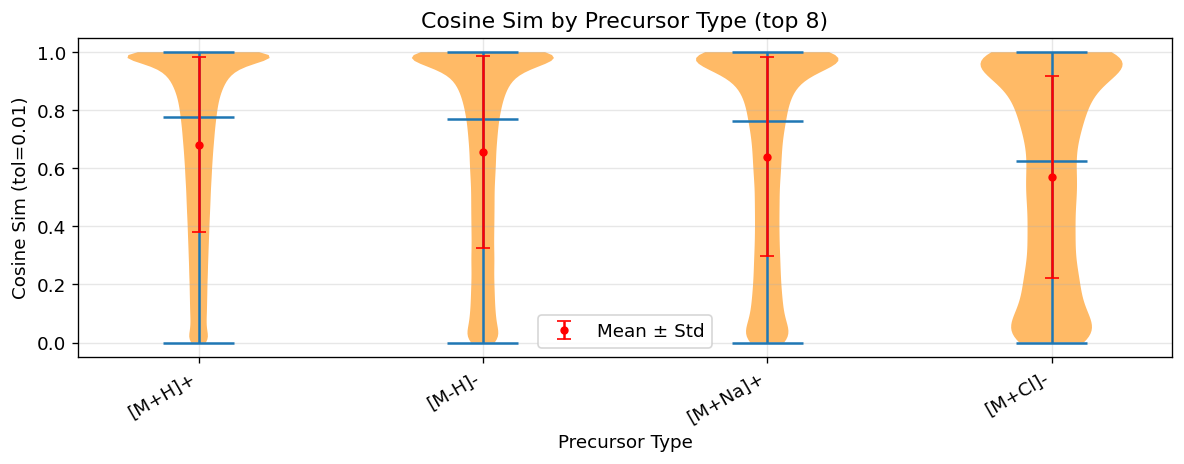

In [11]:
prec_order = df_top.groupby("prec_type")["cos_sim_0.01"].median().sort_values(ascending=False).index.tolist()
groups = [df_top.loc[df_top["prec_type"] == g, "cos_sim_0.01"].dropna().values for g in prec_order]

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(1, len(groups) + 1)
vp = ax.violinplot(groups, positions=x, showmedians=True, showextrema=True)
for body in vp["bodies"]:
    body.set_facecolor("darkorange")
    body.set_alpha(0.6)
means = [g.mean() for g in groups]
stds = [g.std() for g in groups]
ax.errorbar(x, means, yerr=stds, fmt="o", color="red", capsize=4, markersize=4,
            label="Mean ± Std", zorder=5)
ax.set_xticks(x)
ax.set_xticklabels(prec_order, rotation=30, ha="right")
ax.set_title("Cosine Sim by Precursor Type (top 8)")
ax.set_xlabel("Precursor Type")
ax.set_ylabel("Cosine Sim (tol=0.01)")
ax.legend()
plt.tight_layout()
plt.show()

## 6. Performance by Ion Mode

In [12]:
ion_stats = (
    df[df["ion_mode"].isin(["P", "N"])]
    .groupby("ion_mode")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
ion_stats

cos_sim_0.01                 cos_hun                
                 mean  median   count    mean  median   count
ion_mode                                                     
N              0.6510  0.7622  170939  0.6823  0.7960  170939
P              0.6767  0.7740  527737  0.6976  0.7976  527737

## 7. Performance by Fragmentation Mode (HCD vs CID)

In [13]:
frag_stats = (
    df.groupby("frag_mode")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
frag_stats

cos_sim_0.01                 cos_hun                
                  mean  median   count    mean  median   count
frag_mode                                                     
CID             0.5186  0.5237   73094  0.5159  0.5192   73094
HCD             0.6881  0.7911  625582  0.7146  0.8174  625582

## 8. Effect of Collision Energy on Performance

Native CE type per instrument: **NCE (%)** for FT and IT, **ACE (eV)** for QTOF.

In [14]:
# Per-instrument CE analysis using native CE type: QTOF → ACE (eV), FT/IT → NCE (%)
CE_CONFIG = {
    "FT":   {
        "col": "nce",
        "edges": [0, 20, 30, 40, 60, 80, 120, 200],
        "labels": ["0-20", "20-30", "30-40", "40-60", "60-80", "80-120", "120-200"],
        "label": "NCE (%)",
    },
    "QTOF": {
        "col": "ace",
        "edges": [0, 10, 20, 30, 50, 100, 200],
        "labels": ["0-10", "10-20", "20-30", "30-50", "50-100", "100-200"],
        "label": "ACE (eV)",
    },
    "IT": {
        "col": "nce",
        "edges": [0, 20, 30, 40, 60, 80, 120, 200],
        "labels": ["0-20", "20-30", "30-40", "40-60", "60-80", "80-120", "120-200"],
        "label": "NCE (%)",
    },
}

ce_stats = {}
for inst, cfg in CE_CONFIG.items():
    sub = df[df["inst_type"] == inst].copy()
    sub = sub[
        sub[cfg["col"]].notna()
        & (sub[cfg["col"]] > 0)
        & (sub[cfg["col"]] <= cfg["edges"][-1])
    ]
    if len(sub) == 0:
        print(f"\n=== {inst} ({cfg['label']}) — no valid CE data ===")
        continue
    sub["ce_bin"] = pd.cut(sub[cfg["col"]], bins=cfg["edges"], labels=cfg["labels"], right=True)
    stats = (
        sub.groupby("ce_bin", observed=True)[["cos_sim_0.01", "cos_hun"]]
        .agg(["mean", "median", "std", "count"])
        .round(4)
    )
    ce_stats[inst] = (stats, cfg["label"])
    print(f"\n=== {inst} ({cfg['label']}) ===")
    print(stats)


=== FT (NCE (%)) ===
        cos_sim_0.01                         cos_hun                        
                mean  median     std   count    mean  median     std   count
ce_bin                                                                      
0-20          0.7895  0.9330  0.2829  110371  0.8284  0.9443  0.2365  110371
20-30         0.7576  0.8936  0.2881   63159  0.7936  0.9115  0.2533   63159
30-40         0.6234  0.7134  0.3339  122408  0.6511  0.7488  0.3196  122408
40-60         0.6981  0.8126  0.3032  115564  0.7274  0.8395  0.2831  115564
60-80         0.6441  0.7111  0.2993   65558  0.6674  0.7406  0.2877   65558
80-120        0.6291  0.6831  0.2930  105765  0.6454  0.7035  0.2861  105765
120-200       0.6008  0.6439  0.2972   82490  0.6126  0.6576  0.2924   82490

=== QTOF (ACE (eV)) ===
       cos_sim_0.01                       cos_hun                      
               mean  median     std count    mean  median     std count
ce_bin                                 

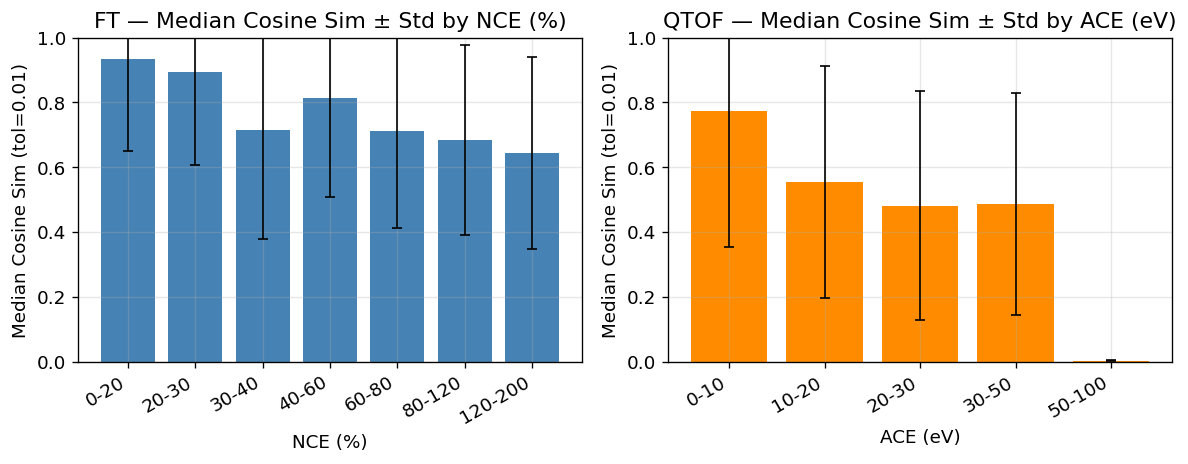

In [15]:
colors = {"FT": "steelblue", "QTOF": "darkorange", "IT": "mediumseagreen"}
n_panels = len(ce_stats)
fig, axes = plt.subplots(1, n_panels, figsize=(5 * n_panels, 4))
if n_panels == 1:
    axes = [axes]

for ax, (inst, (stats, ce_label)) in zip(axes, ce_stats.items()):
    med = stats["cos_sim_0.01"]["median"]
    std = stats["cos_sim_0.01"]["std"]
    x = np.arange(len(med))
    ax.bar(x, med.values, color=colors.get(inst, "steelblue"), edgecolor="none",
           yerr=std.values, capsize=3, error_kw=dict(ecolor="black", elinewidth=1))
    ax.set_xticks(x)
    ax.set_xticklabels(med.index, rotation=30, ha="right")
    ax.set_title(f"{inst} — Median Cosine Sim ± Std by {ce_label}")
    ax.set_xlabel(ce_label)
    ax.set_ylabel("Median Cosine Sim (tol=0.01)")
    ax.set_ylim(0, 1)

plt.tight_layout()
plt.show()


## 9. Performance by Dataset Source

In [16]:
dset_stats = (
    df.groupby("dset")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
dset_stats

cos_sim_0.01                 cos_hun                
                   mean  median   count    mean  median   count
dset                                                           
nist23_hr1       0.6745  0.7782  396028  0.6954  0.8012  396028
nist23_hr2       0.6650  0.7626  302648  0.6919  0.7915  302648

## 10. Performance vs Molecular Properties

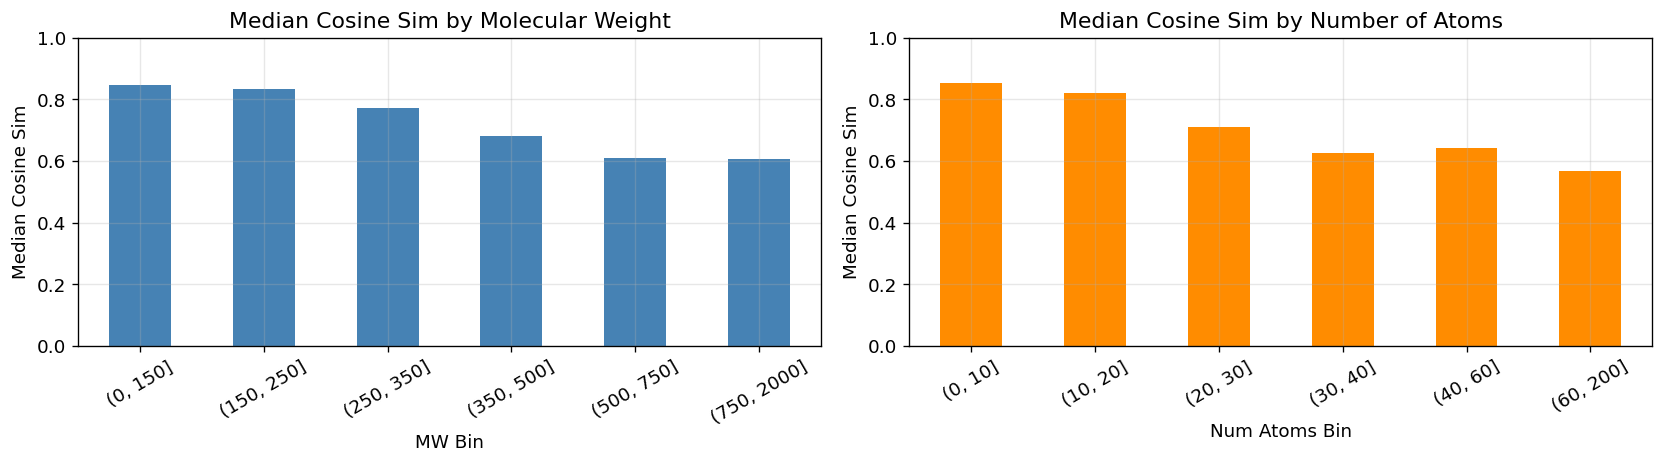

In [17]:
df_mol = df[(df["mw"].notna()) & (df["num_atoms"].notna())].copy()
df_mol["mw_bin"] = pd.cut(df_mol["mw"], bins=[0, 150, 250, 350, 500, 750, 2000], right=True)
df_mol["natoms_bin"] = pd.cut(df_mol["num_atoms"], bins=[0, 10, 20, 30, 40, 60, 200], right=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

mw_med = df_mol.groupby("mw_bin", observed=True)["cos_sim_0.01"].median()
mw_med.plot(kind="bar", ax=axes[0], color="steelblue", edgecolor="none")
axes[0].set_title("Median Cosine Sim by Molecular Weight")
axes[0].set_xlabel("MW Bin")
axes[0].set_ylabel("Median Cosine Sim")
axes[0].set_ylim(0, 1)
axes[0].tick_params(axis="x", rotation=30)

na_med = df_mol.groupby("natoms_bin", observed=True)["cos_sim_0.01"].median()
na_med.plot(kind="bar", ax=axes[1], color="darkorange", edgecolor="none")
axes[1].set_title("Median Cosine Sim by Number of Atoms")
axes[1].set_xlabel("Num Atoms Bin")
axes[1].set_ylabel("Median Cosine Sim")
axes[1].set_ylim(0, 1)
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

## 11. Out-of-Spectrum Probability vs Similarity

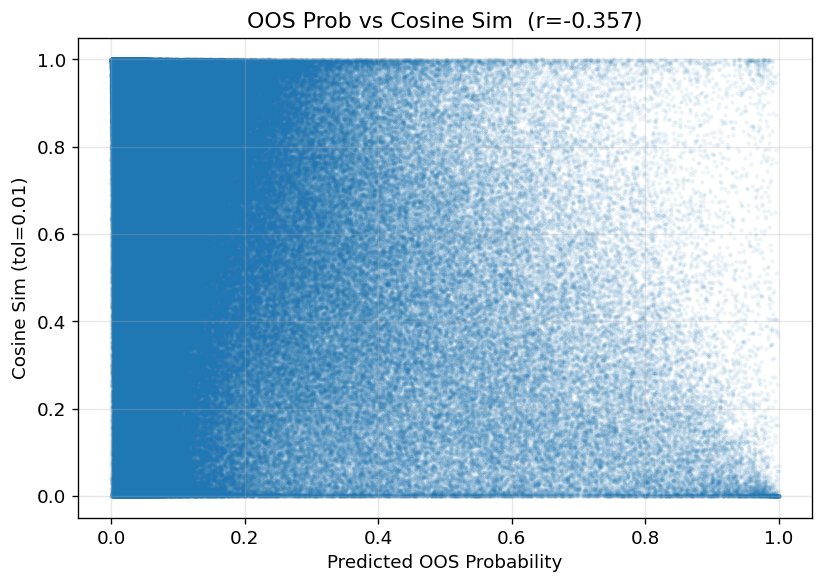

In [18]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(
    df["pred_oos_prob"],
    df["cos_sim_0.01"],
    alpha=0.05,
    s=3,
    rasterized=True,
)
corr = df[["pred_oos_prob", "cos_sim_0.01"]].corr().iloc[0, 1]
ax.set_xlabel("Predicted OOS Probability")
ax.set_ylabel("Cosine Sim (tol=0.01)")
ax.set_title(f"OOS Prob vs Cosine Sim  (r={corr:.3f})")
plt.tight_layout()
plt.show()

In [19]:
df["oos_bin"] = pd.cut(df["pred_oos_prob"], bins=[0, 0.05, 0.1, 0.2, 0.5, 1.0], right=True)
oos_stats = (
    df.groupby("oos_bin", observed=True)[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
oos_stats

cos_sim_0.01                 cos_hun                
                    mean  median   count    mean  median   count
oos_bin                                                         
(0.0, 0.05]       0.7628  0.8996  310410  0.7940  0.9147  310410
(0.05, 0.1]       0.6850  0.7911  127235  0.7142  0.8182  127235
(0.1, 0.2]        0.6342  0.7019  109321  0.6578  0.7274  109321
(0.2, 0.5]        0.5468  0.5651  108843  0.5561  0.5782  108843
(0.5, 1.0]        0.3640  0.3016   42867  0.3500  0.2911   42867

## 12. Top / Bottom Predictions

In [20]:
display_cols = ["spec_id", "mol_id", "smiles", "formula", "prec_type", "inst_type", "cos_sim_0.01", "cos_hun"]

print("=== Top 10 predictions ===")
display(df.nlargest(10, "cos_sim_0.01")[display_cols].reset_index(drop=True))

print("=== Bottom 10 predictions ===")
display(df.nsmallest(10, "cos_sim_0.01")[display_cols].reset_index(drop=True))

=== Top 10 predictions ===


,spec_id,mol_id,smiles,formula,prec_type,inst_type,cos_sim_0.01,cos_hun
0,647170,46162,O=C(O)c1cccc(I)c1,C7H5IO2,[M-H]-,FT,1.000000,1.000000
1,647170,46162,O=C(O)c1cccc(I)c1,C7H5IO2,[M-H]-,FT,1.000000,1.000000
2,747296,18089,CCN(Cc1c(F)cccc1Cl)c1c([N+](=O)[O-])cc(C(F)(F)...,C16H12ClF4N3O4,[M+H]+,FT,1.000000,1.000000
3,1155016,45574,O=C(O)c1cc(Cl)ccc1C(F)(F)F,C8H4ClF3O2,[M-H]-,FT,1.000000,1.000000
4,1252731,22684,COC(=O)C(C)CS(=O)(=O)O,C5H10O5S,[M+Na]+,FT,1.000000,1.000000
5,1188841,51251,OCc1ncccc1F,C6H6FNO,[M+H]+,FT,0.999999,1.000000
6,722931,34132,Cc1ncc(-c2ccnc(Nc3ccc(S(C)(=O)=O)cc3)n2)n1C(C)C,C18H21N5O2S,[M+H]+,FT,0.999999,0.999999
7,1263111,18409,CCNCc1ccccc1,C9H13N,[M+H]+,FT,0.999999,0.999999
8,940532,39589,NNC(=O)CC(F)(F)F,C3H5F3N2O,[M+H]+,FT,0.999999,0.999999
9,551714,27314,COc1ccc(-c2nc3cc([N+](=O)[O-])ccc3[nH]2)cc1,C14H11N3O3,[M-H]-,FT,0.999999,0.999999


=== Bottom 10 predictions ===


,spec_id,mol_id,smiles,formula,prec_type,inst_type,cos_sim_0.01,cos_hun
0,9358,19838,CCOc1cc(=O)oc2ccc(OC)cc12,C12H12O4,[M+H]+,FT,0.0,0.764567
1,9564,13772,CCCC(O)CC,C6H14O,[M+H]+,QTOF,0.0,0.000000
2,9671,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.057358
3,9672,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.028581
4,9673,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.012589
5,9674,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.006699
6,9675,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.002818
7,9676,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.004042
8,9677,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.000000
9,9678,23170,COC(=O)CC(C)=O,C5H8O3,[M+H]+,QTOF,0.0,0.001769


## 13. Performance by ClassyFire Superclass

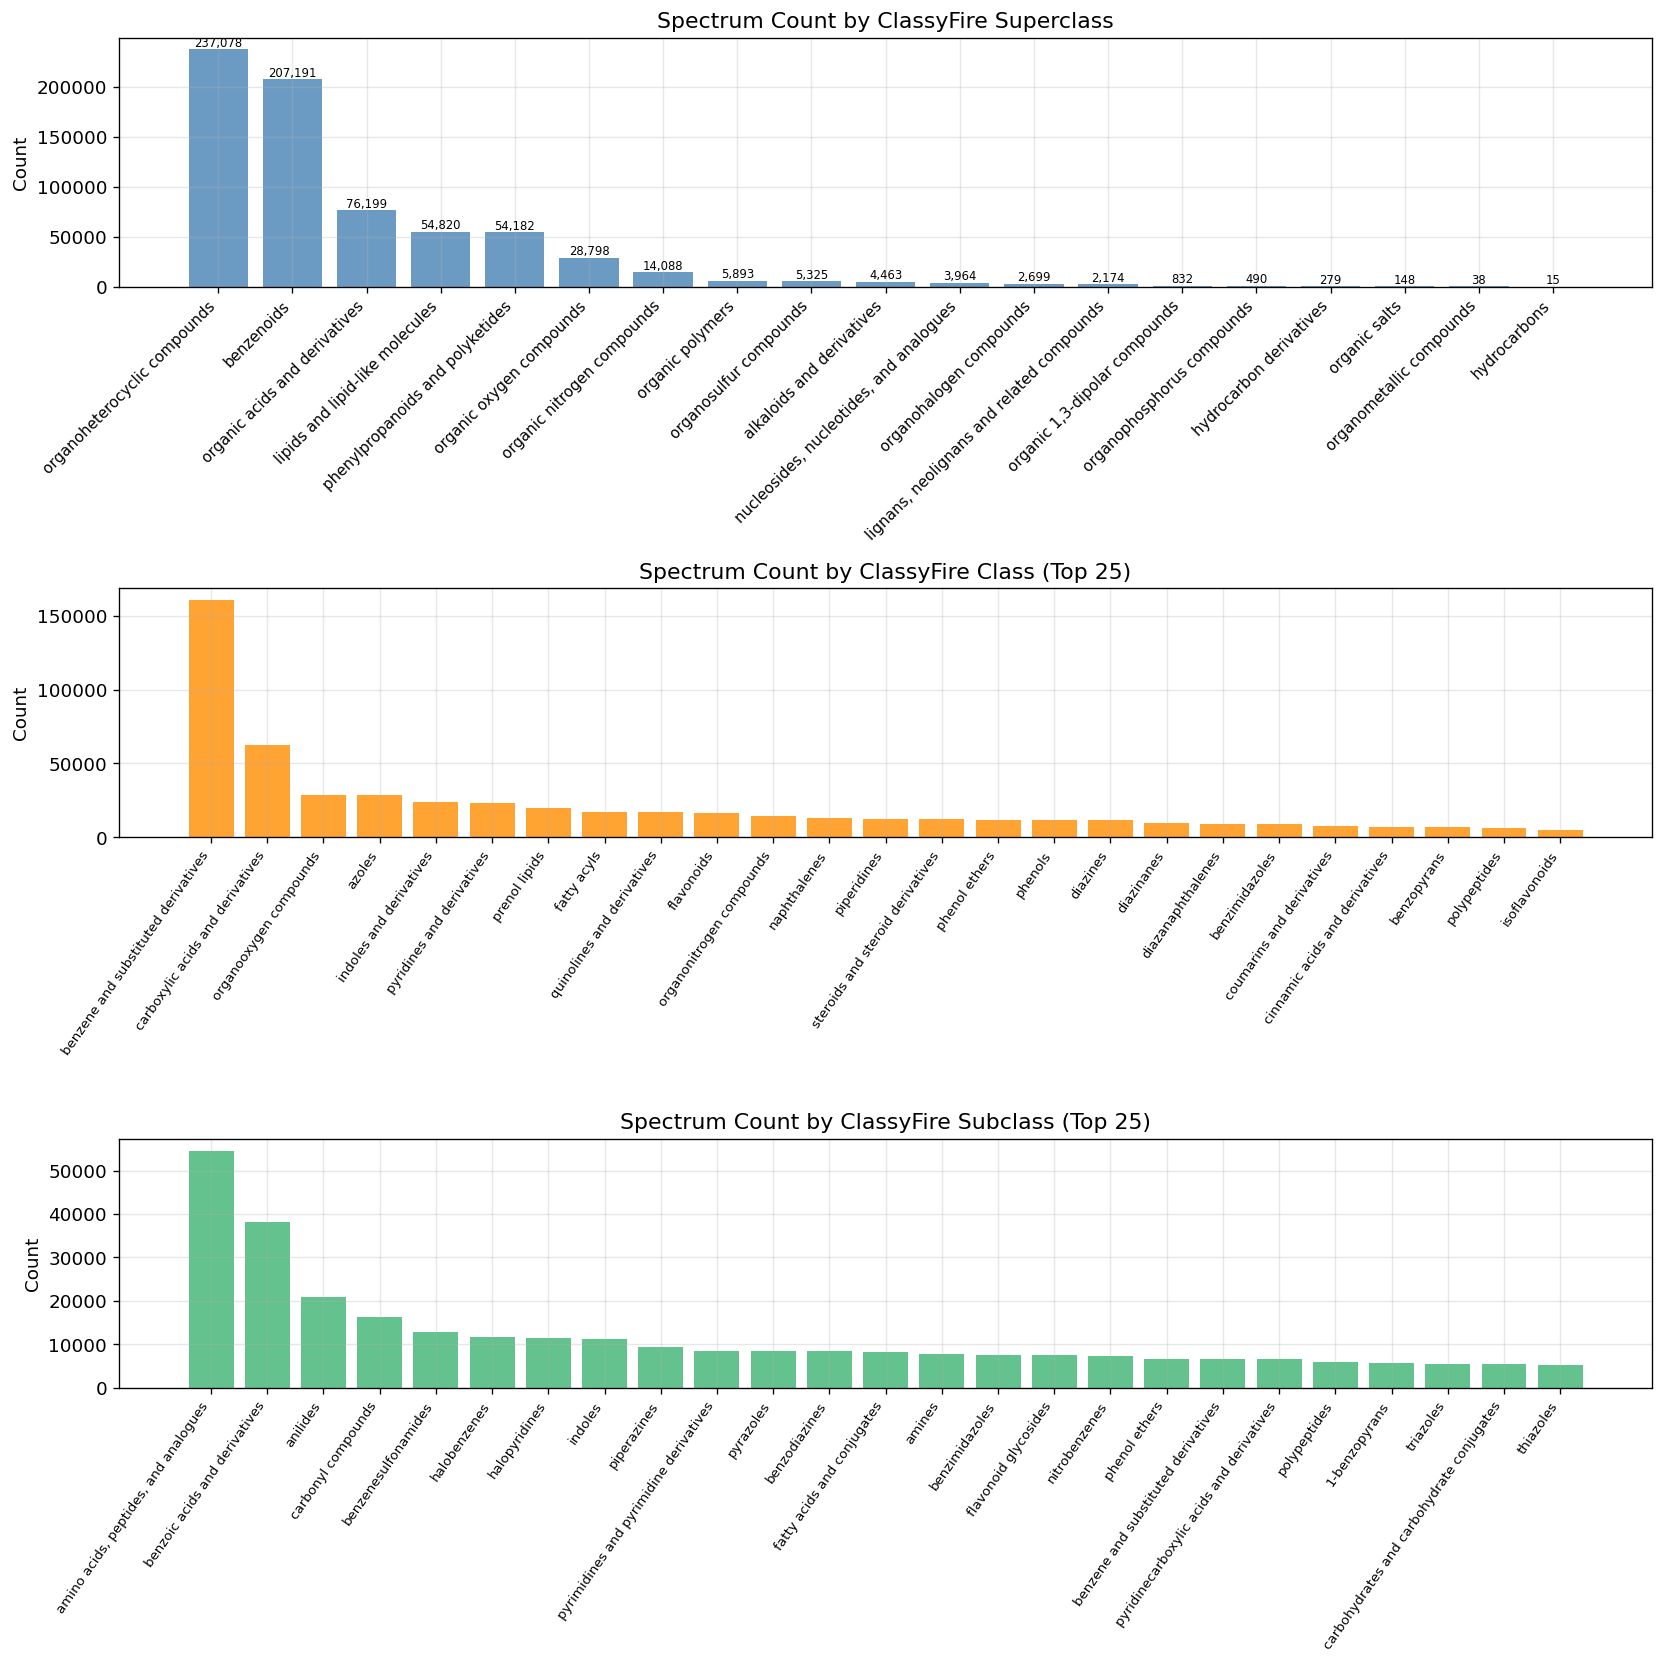

Spectra with no superklass label: 0
Spectra with no klass label:      1,164
Spectra with no subklass label:   0


In [21]:
fig, axes = plt.subplots(3, 1, figsize=(14, 14))

# Superclass distribution (all)
super_counts = df["superklass"].value_counts()
axes[0].bar(range(len(super_counts)), super_counts.values, color="steelblue", alpha=0.8)
axes[0].set_xticks(range(len(super_counts)))
axes[0].set_xticklabels(super_counts.index, rotation=45, ha="right", fontsize=9)
axes[0].set_title("Spectrum Count by ClassyFire Superclass")
axes[0].set_ylabel("Count")
for i, v in enumerate(super_counts.values):
    axes[0].text(i, v + 20, f"{v:,}", ha="center", va="bottom", fontsize=7)

# Class distribution (top 25)
klass_counts = df["klass"].value_counts().head(25)
axes[1].bar(range(len(klass_counts)), klass_counts.values, color="darkorange", alpha=0.8)
axes[1].set_xticks(range(len(klass_counts)))
axes[1].set_xticklabels(klass_counts.index, rotation=55, ha="right", fontsize=8)
axes[1].set_title("Spectrum Count by ClassyFire Class (Top 25)")
axes[1].set_ylabel("Count")

# Subclass distribution (top 25)
sub_counts = df["subklass"].value_counts().head(25)
axes[2].bar(range(len(sub_counts)), sub_counts.values, color="mediumseagreen", alpha=0.8)
axes[2].set_xticks(range(len(sub_counts)))
axes[2].set_xticklabels(sub_counts.index, rotation=55, ha="right", fontsize=8)
axes[2].set_title("Spectrum Count by ClassyFire Subclass (Top 25)")
axes[2].set_ylabel("Count")

plt.tight_layout()
plt.show()

print(f"Spectra with no superklass label: {df['superklass'].isna().sum():,}")
print(f"Spectra with no klass label:      {df['klass'].isna().sum():,}")
print(f"Spectra with no subklass label:   {df['subklass'].isna().sum():,}")

In [22]:
cf_super_stats = (
    df.dropna(subset=["superklass"])
    .groupby("superklass")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
cf_super_stats.sort_values(("cos_sim_0.01", "median"), ascending=False)

cos_sim_0.01                  \
                                                  mean  median   count   
superklass                                                               
nucleosides, nucleotides, and analogues         0.7589  0.9208    3964   
benzenoids                                      0.6929  0.8051  207191   
organic nitrogen compounds                      0.6979  0.8046   14088   
organic acids and derivatives                   0.6749  0.7934   76199   
organohalogen compounds                         0.6330  0.7756    2699   
organosulfur compounds                          0.6563  0.7689    5325   
organoheterocyclic compounds                    0.6667  0.7627  237078   
organic oxygen compounds                        0.6567  0.7479   28798   
phenylpropanoids and polyketides                0.6516  0.7337   54182   
organophosphorus compounds                      0.6262  0.7147     490   
lipids and lipid-like molecules                 0.6345  0.7082   54820   
organic polymers                                0.6181  0.7055    5893   
hydrocarbons                                    0.6314  0.6917      15   
organic 1,3-dipolar compounds                   0.5923  0.6470     832   
alkaloids and derivatives                       0.5774  0.6331    4463   
lignans, neolignans and related compounds       0.5000  0.5108    2174   
hydrocarbon derivatives                         0.4222  0.3659     279   
organic salts                                   0.3910  0.2680     148   
organometallic compounds                        0.3632  0.1779      38   

                                          cos_hun                  
                                             mean  median   count  
superklass                                                         
nucleosides, nucleotides, and analogues    0.7496  0.9147    3964  
benzenoids                                 0.7172  0.8277  207191  
organic nitrogen compounds                 0.7193  0.8295   14088  
organic acids and derivatives              0.6887  0.8101   76199  
organohalogen compounds                    0.6612  0.7992    2699  
organosulfur compounds                     0.7003  0.8192    5325  
organoheterocyclic compounds               0.6889  0.7884  237078  
organic oxygen compounds                   0.6859  0.7803   28798  
phenylpropanoids and polyketides           0.6859  0.7723   54182  
organophosphorus compounds                 0.6573  0.7694     490  
lipids and lipid-like molecules            0.6634  0.7434   54820  
organic polymers                           0.6079  0.7033    5893  
hydrocarbons                               0.6307  0.6926      15  
organic 1,3-dipolar compounds              0.6196  0.6743     832  
alkaloids and derivatives                  0.5858  0.6521    4463  
lignans, neolignans and related compounds  0.5797  0.6312    2174  
hydrocarbon derivatives                    0.3940  0.3426     279  
organic salts                              0.3947  0.2798     148  
organometallic compounds                   0.3632  0.1779      38

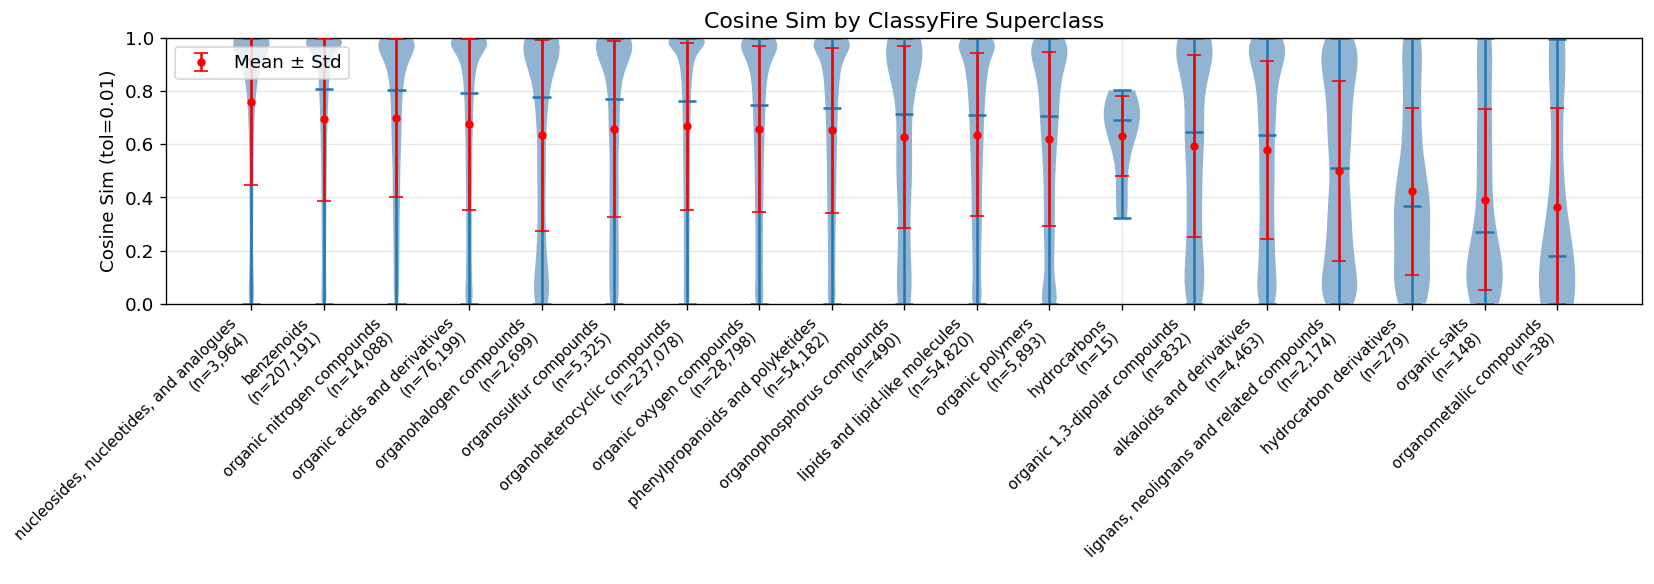

In [23]:
df_cf = df.dropna(subset=["superklass"])
super_order = df_cf.groupby("superklass")["cos_sim_0.01"].median().sort_values(ascending=False).index.tolist()
groups = [df_cf.loc[df_cf["superklass"] == g, "cos_sim_0.01"].values for g in super_order]
counts = [len(g) for g in groups]

fig, ax = plt.subplots(figsize=(14, 5))
x = np.arange(1, len(groups) + 1)
vp = ax.violinplot(groups, positions=x, showmedians=True, showextrema=True)
for body in vp["bodies"]:
    body.set_facecolor("steelblue")
    body.set_alpha(0.6)
means = [g.mean() for g in groups]
stds = [g.std() for g in groups]
ax.errorbar(x, means, yerr=stds, fmt="o", color="red", capsize=4, markersize=4,
            label="Mean ± Std", zorder=5)
ax.set_xticks(x)
ax.set_xticklabels([f"{s}\n(n={c:,})" for s, c in zip(super_order, counts)],
                   rotation=45, ha="right", fontsize=9)
ax.set_title("Cosine Sim by ClassyFire Superclass")
ax.set_ylabel("Cosine Sim (tol=0.01)")
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.show()

## 14. Performance by ClassyFire Class (Top 25)

In [24]:
top25_classes = df["klass"].value_counts().head(25).index.tolist()
df_klass = df[df["klass"].isin(top25_classes)].dropna(subset=["klass"])

cf_klass_stats = (
    df_klass.groupby("klass")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
cf_klass_stats.sort_values(("cos_sim_0.01", "median"), ascending=False)

cos_sim_0.01                 cos_hun  \
                                            mean  median   count    mean   
klass                                                                      
piperidines                               0.7381  0.8673   12086  0.7566   
cinnamic acids and derivatives            0.7195  0.8364    6864  0.7514   
benzimidazoles                            0.7098  0.8268    8689  0.7355   
benzene and substituted derivatives       0.7043  0.8190  160589  0.7270   
indoles and derivatives                   0.6960  0.8145   23625  0.7251   
carboxylic acids and derivatives          0.6835  0.8067   62371  0.6968   
organonitrogen compounds                  0.6979  0.8046   14088  0.7193   
fatty acyls                               0.6908  0.7915   17313  0.7123   
phenols                                   0.6746  0.7895   11381  0.6924   
pyridines and derivatives                 0.6839  0.7863   23324  0.6994   
diazinanes                                0.6983  0.7855    9647  0.7185   
phenol ethers                             0.6854  0.7788   11500  0.7092   
naphthalenes                              0.6712  0.7754   12772  0.7157   
quinolines and derivatives                0.6711  0.7677   17306  0.6947   
azoles                                    0.6696  0.7628   28362  0.6903   
organooxygen compounds                    0.6564  0.7474   28726  0.6857   
diazines                                  0.6573  0.7473   11329  0.6786   
flavonoids                                0.6670  0.7472   16284  0.7145   
diazanaphthalenes                         0.6568  0.7359    8873  0.6743   
polypeptides                              0.6181  0.7055    5893  0.6079   
coumarins and derivatives                 0.6352  0.7054    7396  0.6555   
prenol lipids                             0.5992  0.6450   19561  0.6295   
isoflavonoids                             0.5947  0.6235    5042  0.6207   
steroids and steroid derivatives          0.5792  0.6130   12069  0.6062   
benzopyrans                               0.5455  0.5421    6782  0.5796   

                                                     
                                     median   count  
klass                                                
piperidines                          0.8807   12086  
cinnamic acids and derivatives       0.8619    6864  
benzimidazoles                       0.8479    8689  
benzene and substituted derivatives  0.8385  160589  
indoles and derivatives              0.8450   23625  
carboxylic acids and derivatives     0.8217   62371  
organonitrogen compounds             0.8295   14088  
fatty acyls                          0.8148   17313  
phenols                              0.8094   11381  
pyridines and derivatives            0.8044   23324  
diazinanes                           0.8050    9647  
phenol ethers                        0.8014   11500  
naphthalenes                         0.8195   12772  
quinolines and derivatives           0.7924   17306  
azoles                               0.7865   28362  
organooxygen compounds               0.7799   28726  
diazines                             0.7714   11329  
flavonoids                           0.7926   16284  
diazanaphthalenes                    0.7572    8873  
polypeptides                         0.7033    5893  
coumarins and derivatives            0.7308    7396  
prenol lipids                        0.6843   19561  
isoflavonoids                        0.6597    5042  
steroids and steroid derivatives     0.6515   12069  
benzopyrans                          0.5934    6782

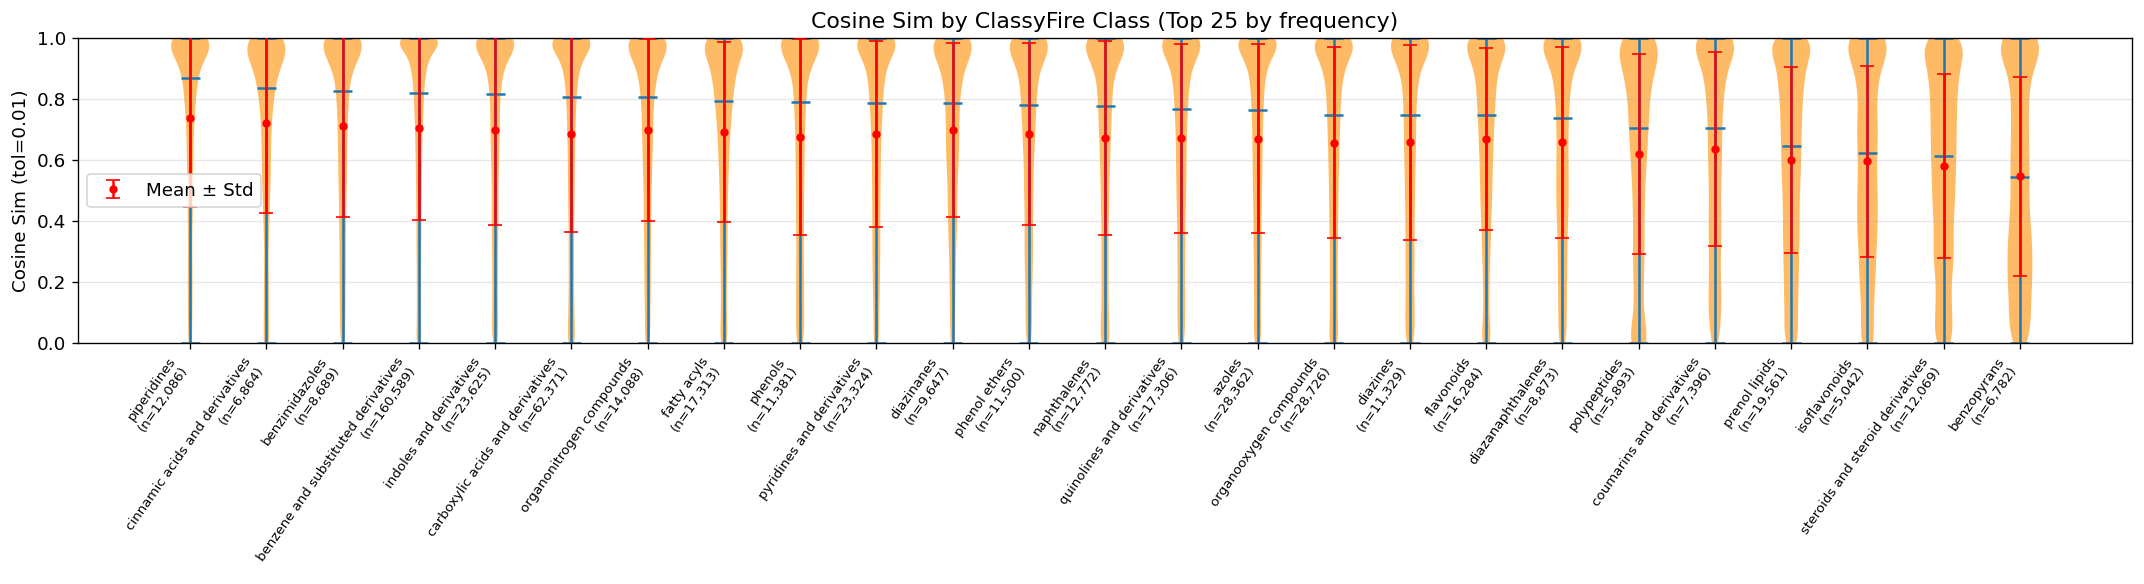

In [25]:
klass_order = df_klass.groupby("klass")["cos_sim_0.01"].median().sort_values(ascending=False).index.tolist()
groups = [df_klass.loc[df_klass["klass"] == g, "cos_sim_0.01"].values for g in klass_order]
counts = [len(g) for g in groups]

fig, ax = plt.subplots(figsize=(18, 5))
x = np.arange(1, len(groups) + 1)
vp = ax.violinplot(groups, positions=x, showmedians=True, showextrema=True)
for body in vp["bodies"]:
    body.set_facecolor("darkorange")
    body.set_alpha(0.6)

means = [g.mean() for g in groups]
stds = [g.std() for g in groups]
ax.errorbar(x, means, yerr=stds, fmt="o", color="red", capsize=4, markersize=4,
            label="Mean ± Std", zorder=5)

ax.set_xticks(x)
ax.set_xticklabels([f"{k}\n(n={c:,})" for k, c in zip(klass_order, counts)], rotation=55, ha="right", fontsize=8)
ax.set_title("Cosine Sim by ClassyFire Class (Top 25 by frequency)")
ax.set_ylabel("Cosine Sim (tol=0.01)")
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.show()

## 15. Performance by ClassyFire Subclass (Top 25)

In [26]:
top25_subklasses = df["subklass"].value_counts().head(25).index.tolist()
df_sub = df[df["subklass"].isin(top25_subklasses)].dropna(subset=["subklass"])

cf_sub_stats = (
    df_sub.groupby("subklass")[["cos_sim_0.01", "cos_hun"]]
    .agg(["mean", "median", "count"])
    .round(4)
)
cf_sub_stats.sort_values(("cos_sim_0.01", "median"), ascending=False)

cos_sim_0.01                cos_hun  \
                                                  mean  median  count    mean   
subklass                                                                        
halobenzenes                                    0.7585  0.8819  11685  0.7768   
benzene and substituted derivatives             0.7214  0.8507   6563  0.7356   
anilides                                        0.7376  0.8496  20913  0.7594   
benzimidazoles                                  0.7146  0.8343   7461  0.7406   
benzoic acids and derivatives                   0.7120  0.8336  38187  0.7390   
amino acids, peptides, and analogues            0.6951  0.8215  54592  0.7089   
fatty acids and conjugates                      0.7135  0.8199   8269  0.7201   
thiazoles                                       0.6976  0.8177   5233  0.7077   
pyridinecarboxylic acids and derivatives        0.6965  0.8149   6511  0.7093   
amines                                          0.7064  0.8129   7775  0.7315   
triazoles                                       0.6899  0.8061   5564  0.7206   
indoles                                         0.6884  0.8027  11313  0.7137   
phenol ethers                                   0.6976  0.7942   6715  0.7244   
carbonyl compounds                              0.6911  0.7906  16292  0.7129   
piperazines                                     0.6973  0.7846   9459  0.7178   
flavonoid glycosides                            0.6829  0.7826   7436  0.7569   
halopyridines                                   0.6789  0.7774  11569  0.6936   
pyrimidines and pyrimidine derivatives          0.6679  0.7673   8480  0.6915   
benzenesulfonamides                             0.6446  0.7354  12740  0.6785   
benzodiazines                                   0.6553  0.7335   8389  0.6733   
pyrazoles                                       0.6533  0.7169   8446  0.6761   
polypeptides                                    0.6181  0.7055   5893  0.6079   
carbohydrates and carbohydrate conjugates       0.6133  0.6785   5437  0.6411   
nitrobenzenes                                   0.6008  0.6494   7307  0.6199   
1-benzopyrans                                   0.5516  0.5565   5665  0.5889   

                                                          
                                           median  count  
subklass                                                  
halobenzenes                               0.8918  11685  
benzene and substituted derivatives        0.8632   6563  
anilides                                   0.8650  20913  
benzimidazoles                             0.8540   7461  
benzoic acids and derivatives              0.8552  38187  
amino acids, peptides, and analogues       0.8357  54592  
fatty acids and conjugates                 0.8309   8269  
thiazoles                                  0.8270   5233  
pyridinecarboxylic acids and derivatives   0.8337   6511  
amines                                     0.8419   7775  
triazoles                                  0.8360   5564  
indoles                                    0.8290  11313  
phenol ethers                              0.8162   6715  
carbonyl compounds                         0.8082  16292  
piperazines                                0.8046   9459  
flavonoid glycosides                       0.8453   7436  
halopyridines                              0.7898  11569  
pyrimidines and pyrimidine derivatives     0.7941   8480  
benzenesulfonamides                        0.7740  12740  
benzodiazines                              0.7548   8389  
pyrazoles                                  0.7421   8446  
polypeptides                               0.7033   5893  
carbohydrates and carbohydrate conjugates  0.7189   5437  
nitrobenzenes                              0.6761   7307  
1-benzopyrans                              0.6076   5665

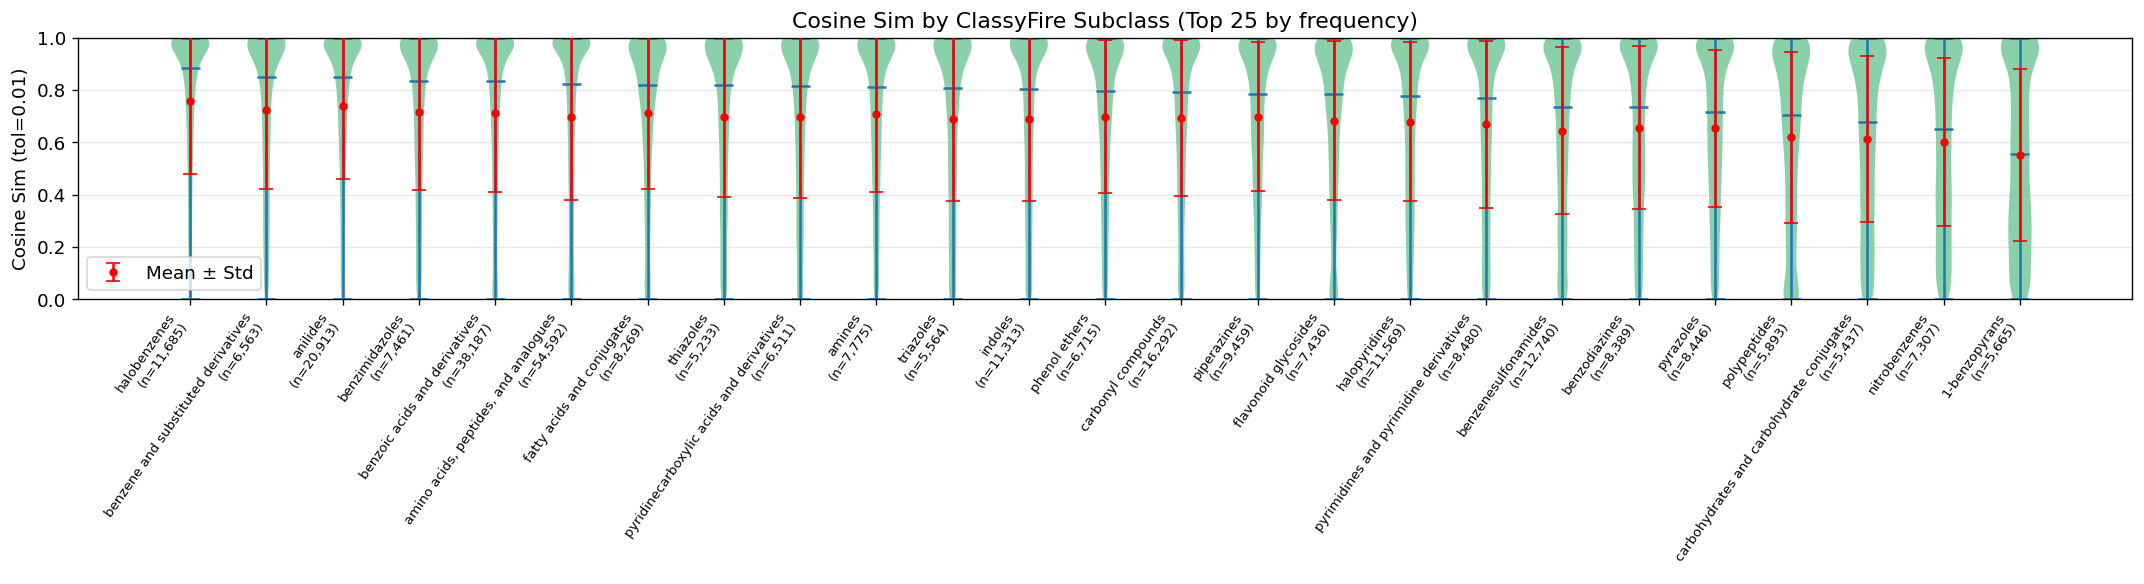

In [27]:
sub_order = df_sub.groupby("subklass")["cos_sim_0.01"].median().sort_values(ascending=False).index.tolist()
groups = [df_sub.loc[df_sub["subklass"] == g, "cos_sim_0.01"].values for g in sub_order]
counts = [len(g) for g in groups]

fig, ax = plt.subplots(figsize=(18, 5))
x = np.arange(1, len(groups) + 1)
vp = ax.violinplot(groups, positions=x, showmedians=True, showextrema=True)
for body in vp["bodies"]:
    body.set_facecolor("mediumseagreen")
    body.set_alpha(0.6)

means = [g.mean() for g in groups]
stds = [g.std() for g in groups]
ax.errorbar(x, means, yerr=stds, fmt="o", color="red", capsize=4, markersize=4,
            label="Mean ± Std", zorder=5)

ax.set_xticks(x)
ax.set_xticklabels([f"{s}\n(n={c:,})" for s, c in zip(sub_order, counts)], rotation=55, ha="right", fontsize=8)
ax.set_title("Cosine Sim by ClassyFire Subclass (Top 25 by frequency)")
ax.set_ylabel("Cosine Sim (tol=0.01)")
ax.set_ylim(0, 1)
ax.legend()
plt.tight_layout()
plt.show()

## 16. Performance Bias by ClassyFire Category

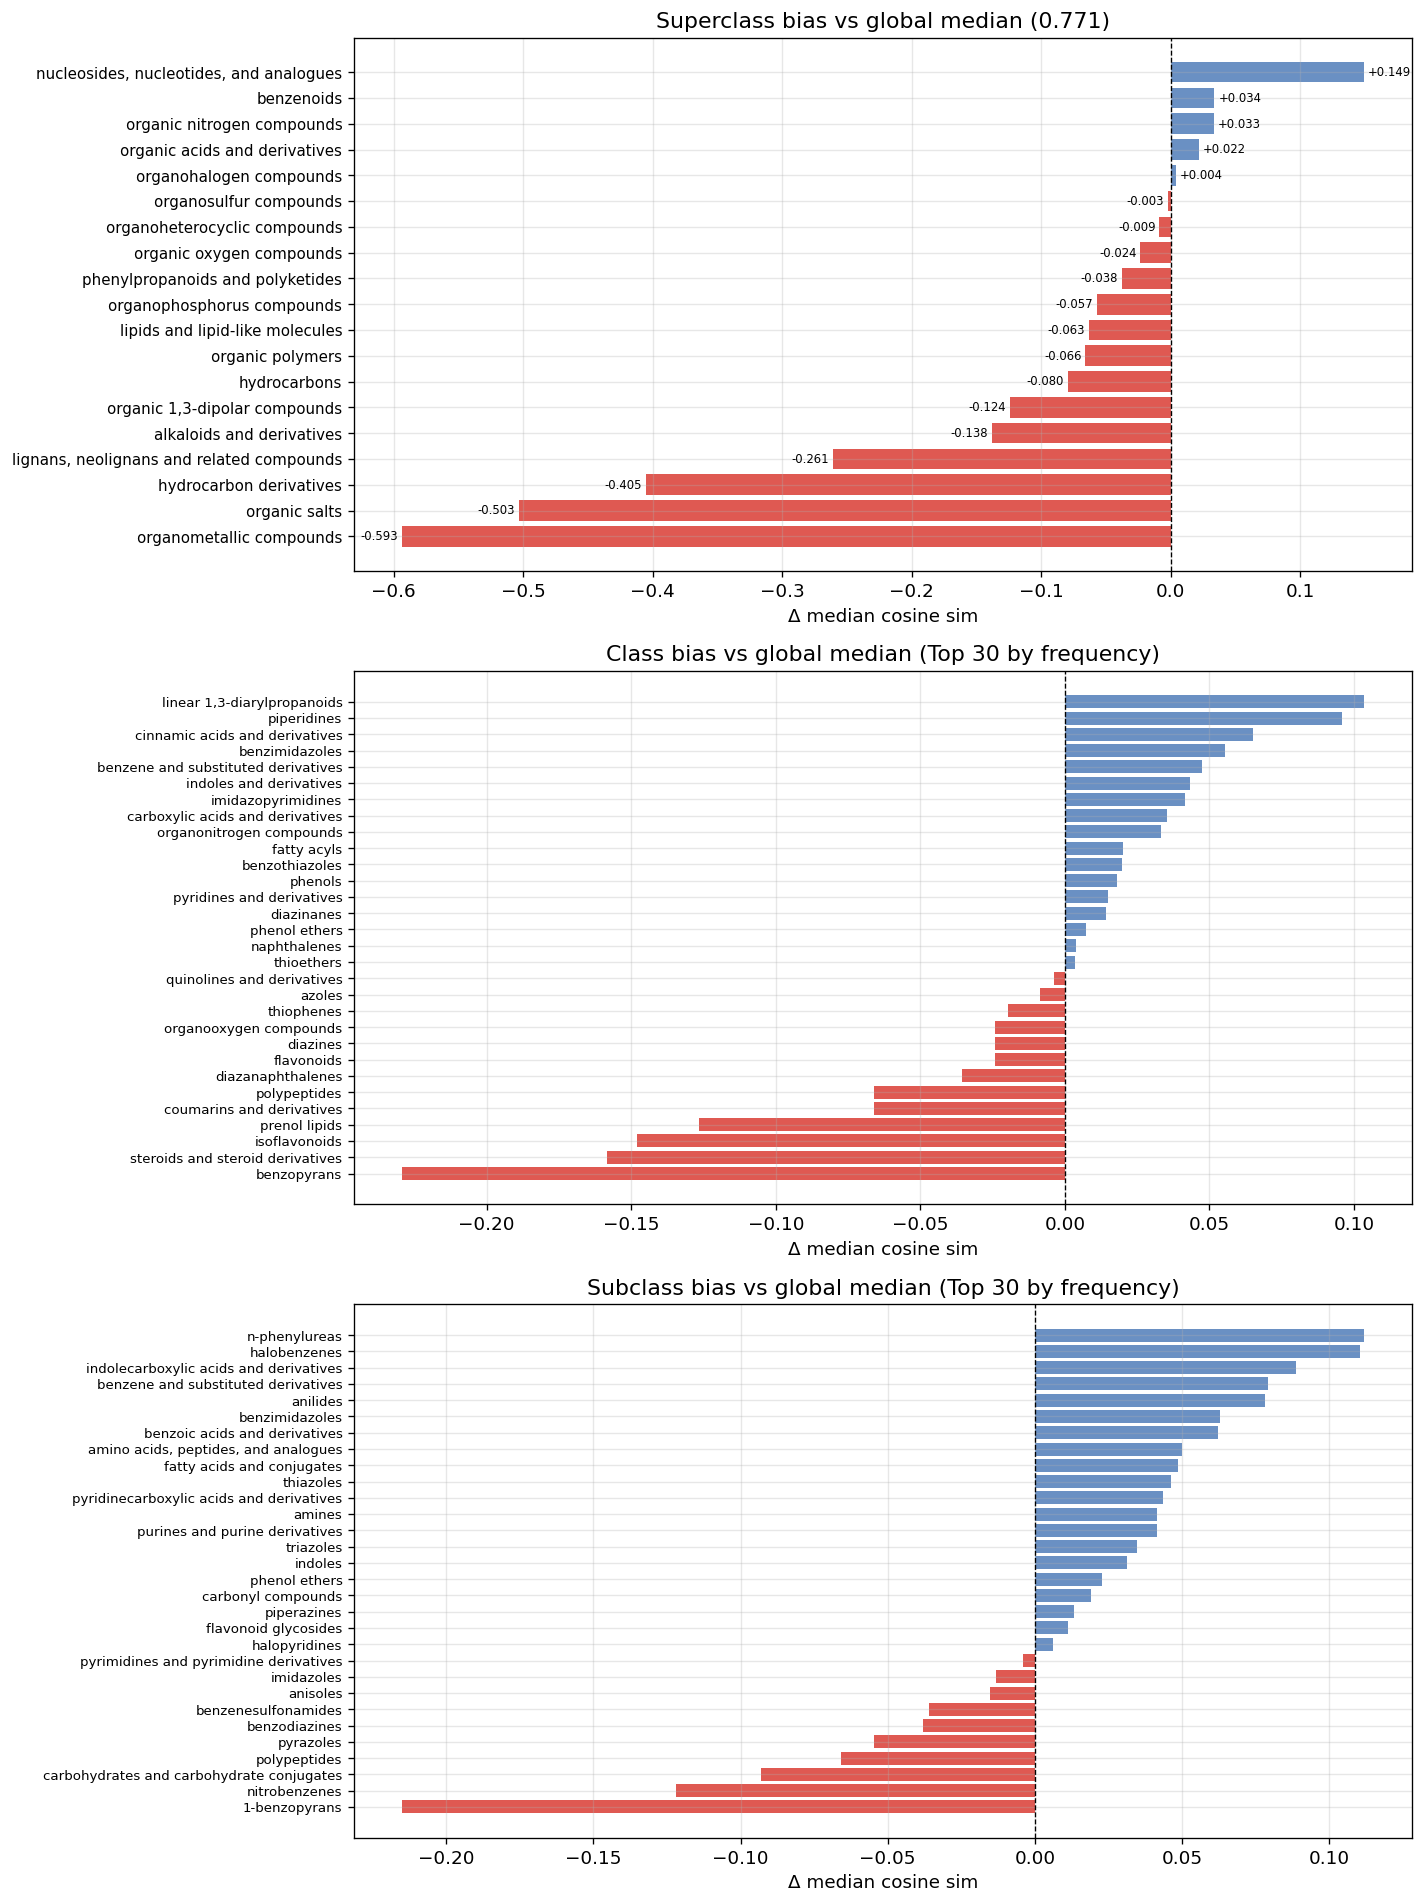

In [28]:
global_median = df["cos_sim_0.01"].median()

fig, axes = plt.subplots(3, 1, figsize=(12, 16))

# --- Superclass bias ---
super_med = (
    df.dropna(subset=["superklass"])
    .groupby("superklass")["cos_sim_0.01"]
    .median()
    .sort_values()
)
super_bias = super_med - global_median
colors = ["#d73027" if v < 0 else "#4575b4" for v in super_bias]
axes[0].barh(range(len(super_bias)), super_bias.values, color=colors, alpha=0.8)
axes[0].set_yticks(range(len(super_bias)))
axes[0].set_yticklabels(super_bias.index, fontsize=9)
axes[0].axvline(0, color="black", linewidth=0.8, linestyle="--")
axes[0].set_title(f"Superclass bias vs global median ({global_median:.3f})")
axes[0].set_xlabel("Δ median cosine sim")
for i, v in enumerate(super_bias.values):
    axes[0].text(v + (0.003 if v >= 0 else -0.003), i, f"{v:+.3f}",
                 va="center", ha="left" if v >= 0 else "right", fontsize=7)

# --- Class bias (top 30 by count) ---
top30_classes = df["klass"].value_counts().head(30).index
klass_med = (
    df[df["klass"].isin(top30_classes)]
    .dropna(subset=["klass"])
    .groupby("klass")["cos_sim_0.01"]
    .median()
    .sort_values()
)
klass_bias = klass_med - global_median
colors = ["#d73027" if v < 0 else "#4575b4" for v in klass_bias]
axes[1].barh(range(len(klass_bias)), klass_bias.values, color=colors, alpha=0.8)
axes[1].set_yticks(range(len(klass_bias)))
axes[1].set_yticklabels(klass_bias.index, fontsize=8)
axes[1].axvline(0, color="black", linewidth=0.8, linestyle="--")
axes[1].set_title("Class bias vs global median (Top 30 by frequency)")
axes[1].set_xlabel("Δ median cosine sim")

# --- Subclass bias (top 30 by count) ---
top30_sub = df["subklass"].value_counts().head(30).index
sub_med = (
    df[df["subklass"].isin(top30_sub)]
    .dropna(subset=["subklass"])
    .groupby("subklass")["cos_sim_0.01"]
    .median()
    .sort_values()
)
sub_bias = sub_med - global_median
colors = ["#d73027" if v < 0 else "#4575b4" for v in sub_bias]
axes[2].barh(range(len(sub_bias)), sub_bias.values, color=colors, alpha=0.8)
axes[2].set_yticks(range(len(sub_bias)))
axes[2].set_yticklabels(sub_bias.index, fontsize=8)
axes[2].axvline(0, color="black", linewidth=0.8, linestyle="--")
axes[2].set_title("Subclass bias vs global median (Top 30 by frequency)")
axes[2].set_xlabel("Δ median cosine sim")

plt.tight_layout()
plt.show()

/tmp/ipykernel_3709489/2156949452.py:75: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


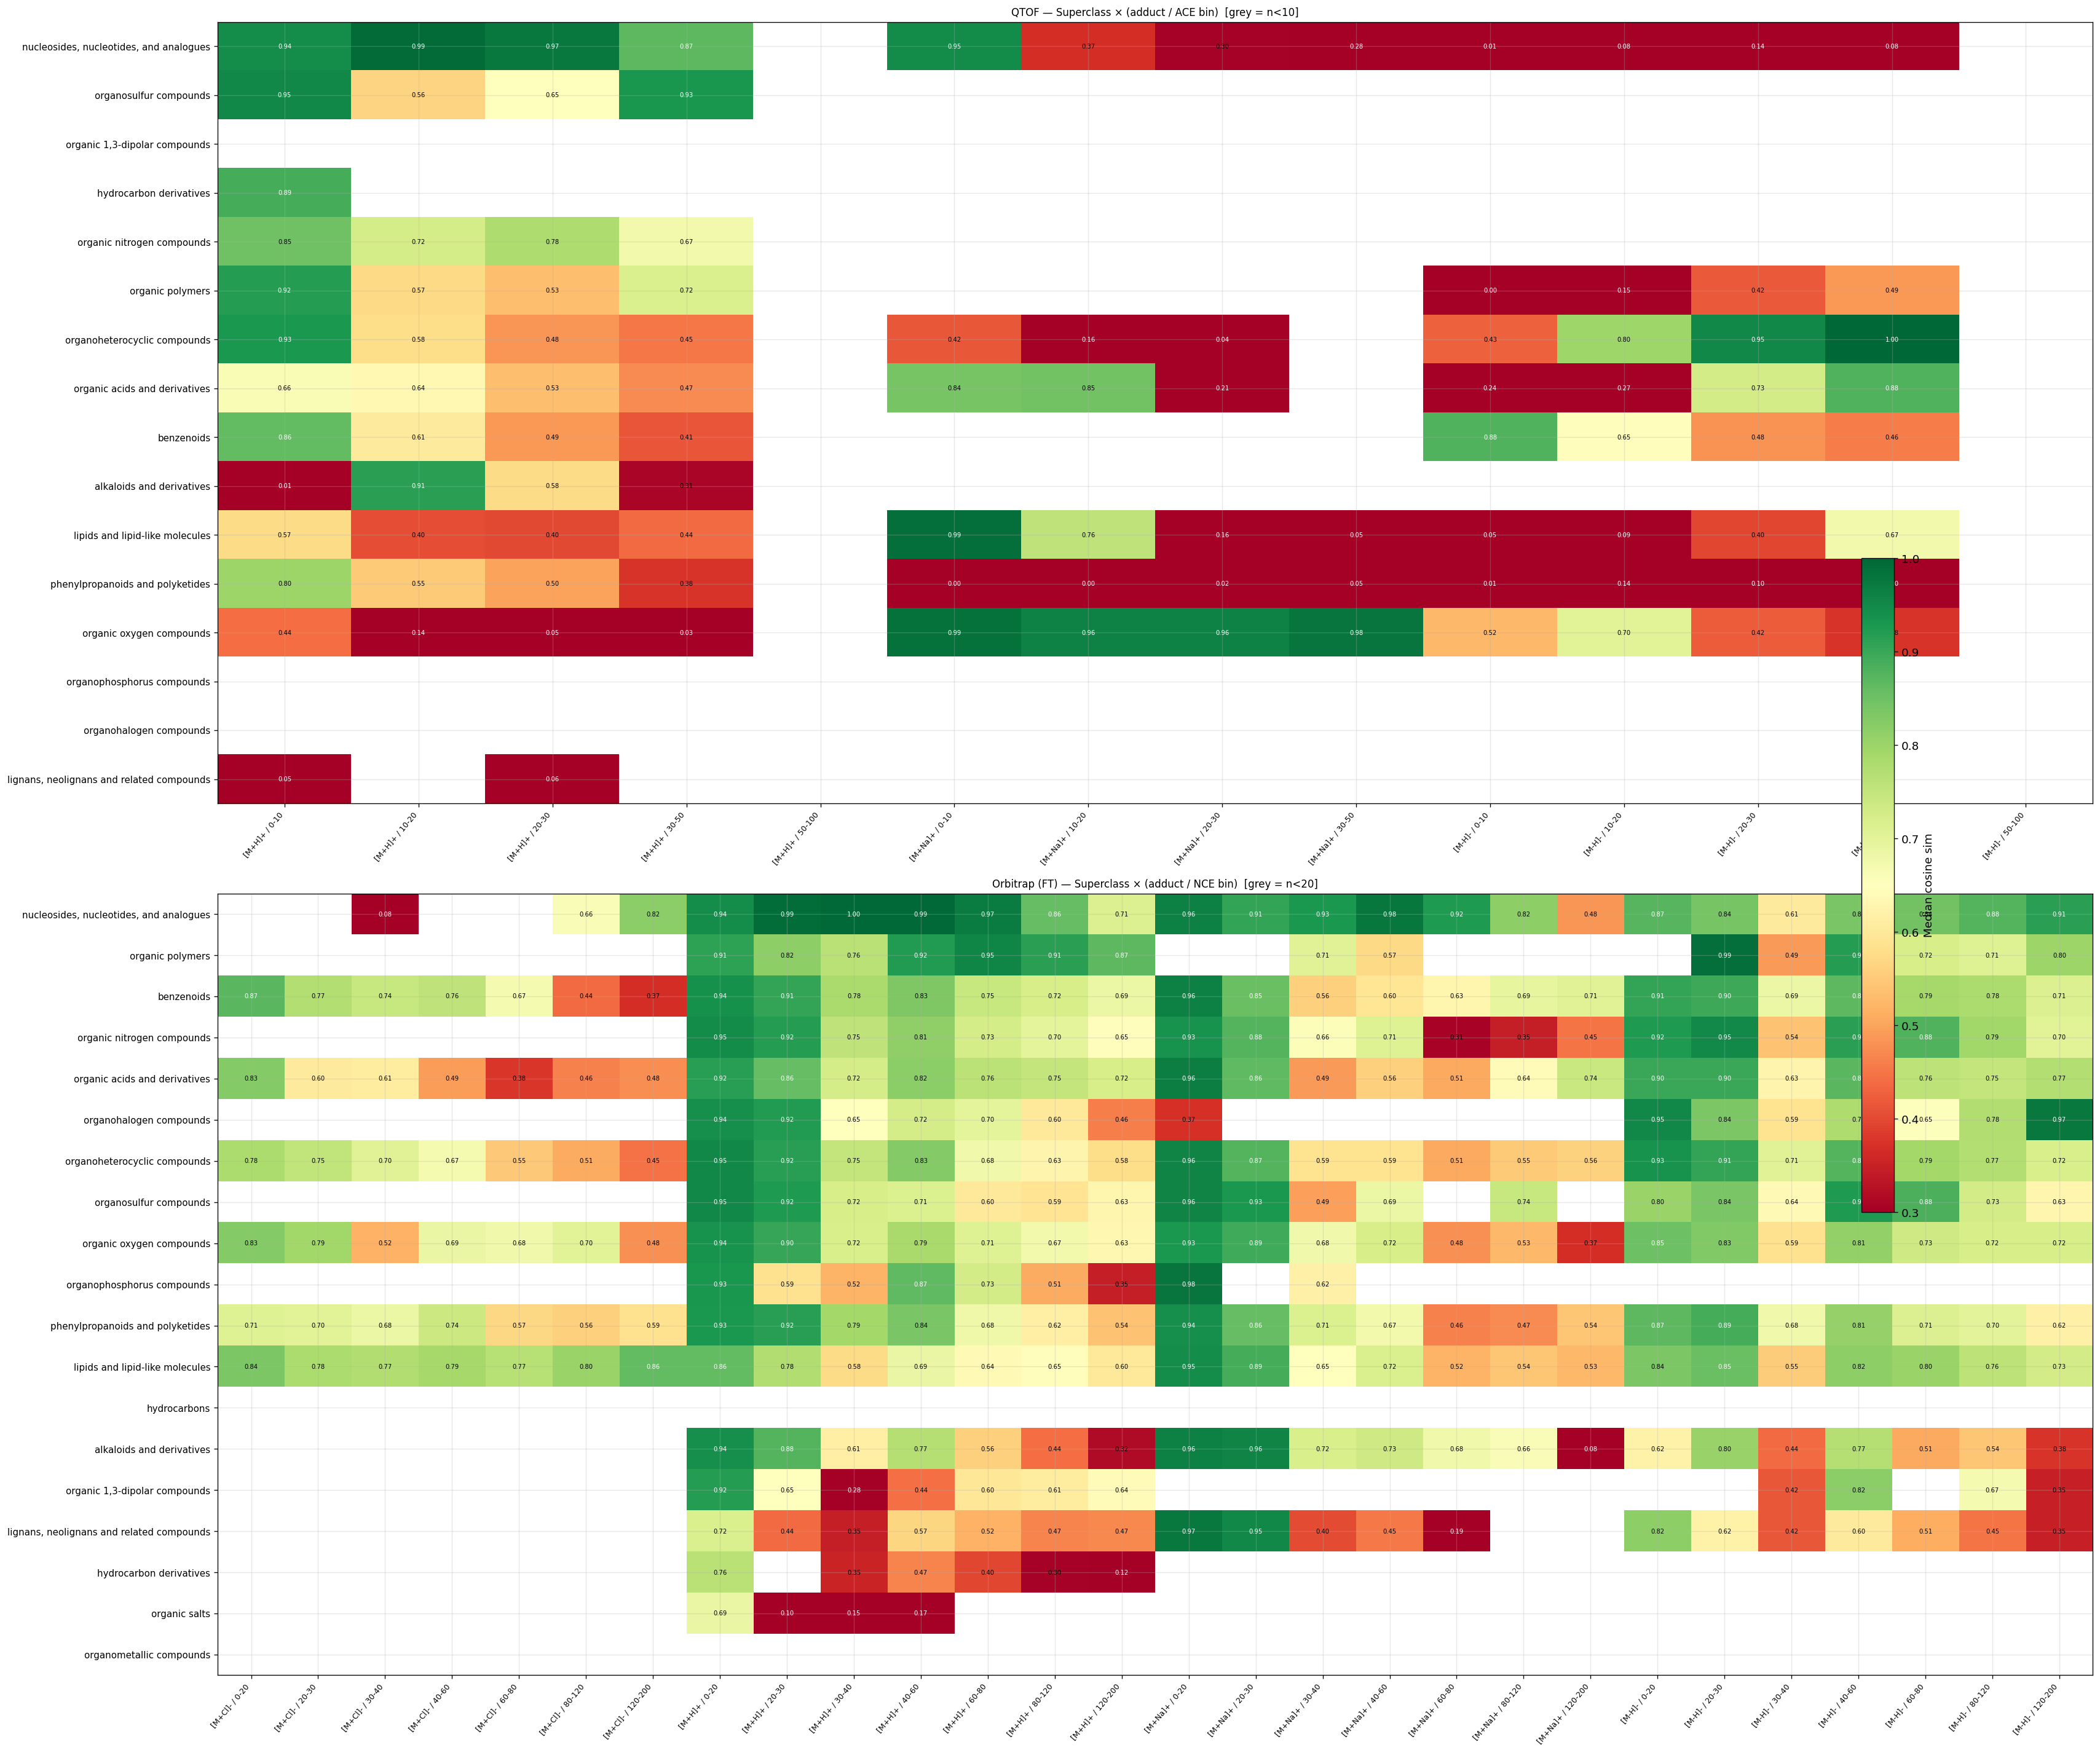

QTOF  heatmap: (16, 14)  non-null cells: 101
FT    heatmap: (19, 28)  non-null cells: 332


In [29]:
main_adducts = ["[M+H]+", "[M-H]-", "[M+Na]+", "[M+Cl]-"]


def make_cf_heatmap(df_in, inst_label, cf_col, min_n=20):
    """Return pivot table (rows=cf_col, cols=adduct/CE bin) of median cosine sim.

    Uses ACE (eV) for QTOF and NCE (%) for FT/IT, with instrument-specific bin edges
    defined in CE_CONFIG.
    """
    cfg = CE_CONFIG[inst_label]
    ce_col = cfg["col"]
    ce_edges = cfg["edges"]
    ce_labels = cfg["labels"]
    ce_label = cfg["label"]

    d = df_in[
        df_in["prec_type"].isin(main_adducts)
        & df_in[ce_col].notna()
        & (df_in[ce_col] > 0)
        & (df_in[ce_col] <= ce_edges[-1])
        & df_in["inst_type"].eq(inst_label)
        & df_in[cf_col].notna()
    ].copy()
    d["ce_bin"] = pd.cut(d[ce_col], bins=ce_edges, labels=ce_labels, right=True)
    d["adduct_ce"] = d["prec_type"] + " / " + d["ce_bin"].astype(str)
    piv = (
        d.groupby([cf_col, "adduct_ce"])["cos_sim_0.01"]
        .agg(["median", "count"])
        .reset_index()
    )
    piv.loc[piv["count"] < min_n, "median"] = float("nan")
    heat = piv.pivot(index=cf_col, columns="adduct_ce", values="median")
    # row order: by overall median within this slice
    row_ord = d.groupby(cf_col)["cos_sim_0.01"].median().sort_values(ascending=False).index
    heat = heat.reindex(row_ord)
    # column order: by adduct then CE bin rank
    col_ord = sorted(
        heat.columns,
        key=lambda x: (
            x.split(" / ")[0],
            ce_labels.index(x.split(" / ")[1]) if x.split(" / ")[1] in ce_labels else 99,
        ),
    )
    return heat[col_ord]


def plot_heatmap(heat, title, ax):
    im = ax.imshow(heat.values, aspect="auto", cmap="RdYlGn", vmin=0.3, vmax=1.0)
    ax.set_xticks(range(len(heat.columns)))
    ax.set_xticklabels(heat.columns, rotation=50, ha="right", fontsize=7.5)
    ax.set_yticks(range(len(heat.index)))
    ax.set_yticklabels(heat.index, fontsize=9)
    ax.set_title(title, fontsize=10)
    for i in range(len(heat.index)):
        for j in range(len(heat.columns)):
            v = heat.values[i, j]
            if not np.isnan(v):
                ax.text(
                    j, i, f"{v:.2f}", ha="center", va="center", fontsize=6,
                    color="black" if 0.3 < v < 0.85 else "white",
                )
    return im


heat_qt = make_cf_heatmap(df, "QTOF", "superklass", min_n=10)
heat_ft = make_cf_heatmap(df, "FT",   "superklass", min_n=20)

n_cols = max(len(heat_qt.columns), len(heat_ft.columns))
n_rows = max(len(heat_qt.index),   len(heat_ft.index))

fig, axes = plt.subplots(2, 1, figsize=(n_cols * 0.95 + 2, n_rows * 1.1 + 3))
im0 = plot_heatmap(heat_qt, "QTOF — Superclass × (adduct / ACE bin)  [grey = n<10]",  axes[0])
im1 = plot_heatmap(heat_ft, "Orbitrap (FT) — Superclass × (adduct / NCE bin)  [grey = n<20]", axes[1])
fig.colorbar(im1, ax=axes, label="Median cosine sim", fraction=0.02, pad=0.04)
plt.tight_layout()
plt.show()

print(f"QTOF  heatmap: {heat_qt.shape}  non-null cells: {heat_qt.notna().sum().sum()}")
print(f"FT    heatmap: {heat_ft.shape}  non-null cells: {heat_ft.notna().sum().sum()}")

/tmp/ipykernel_3709489/2457587856.py:14: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


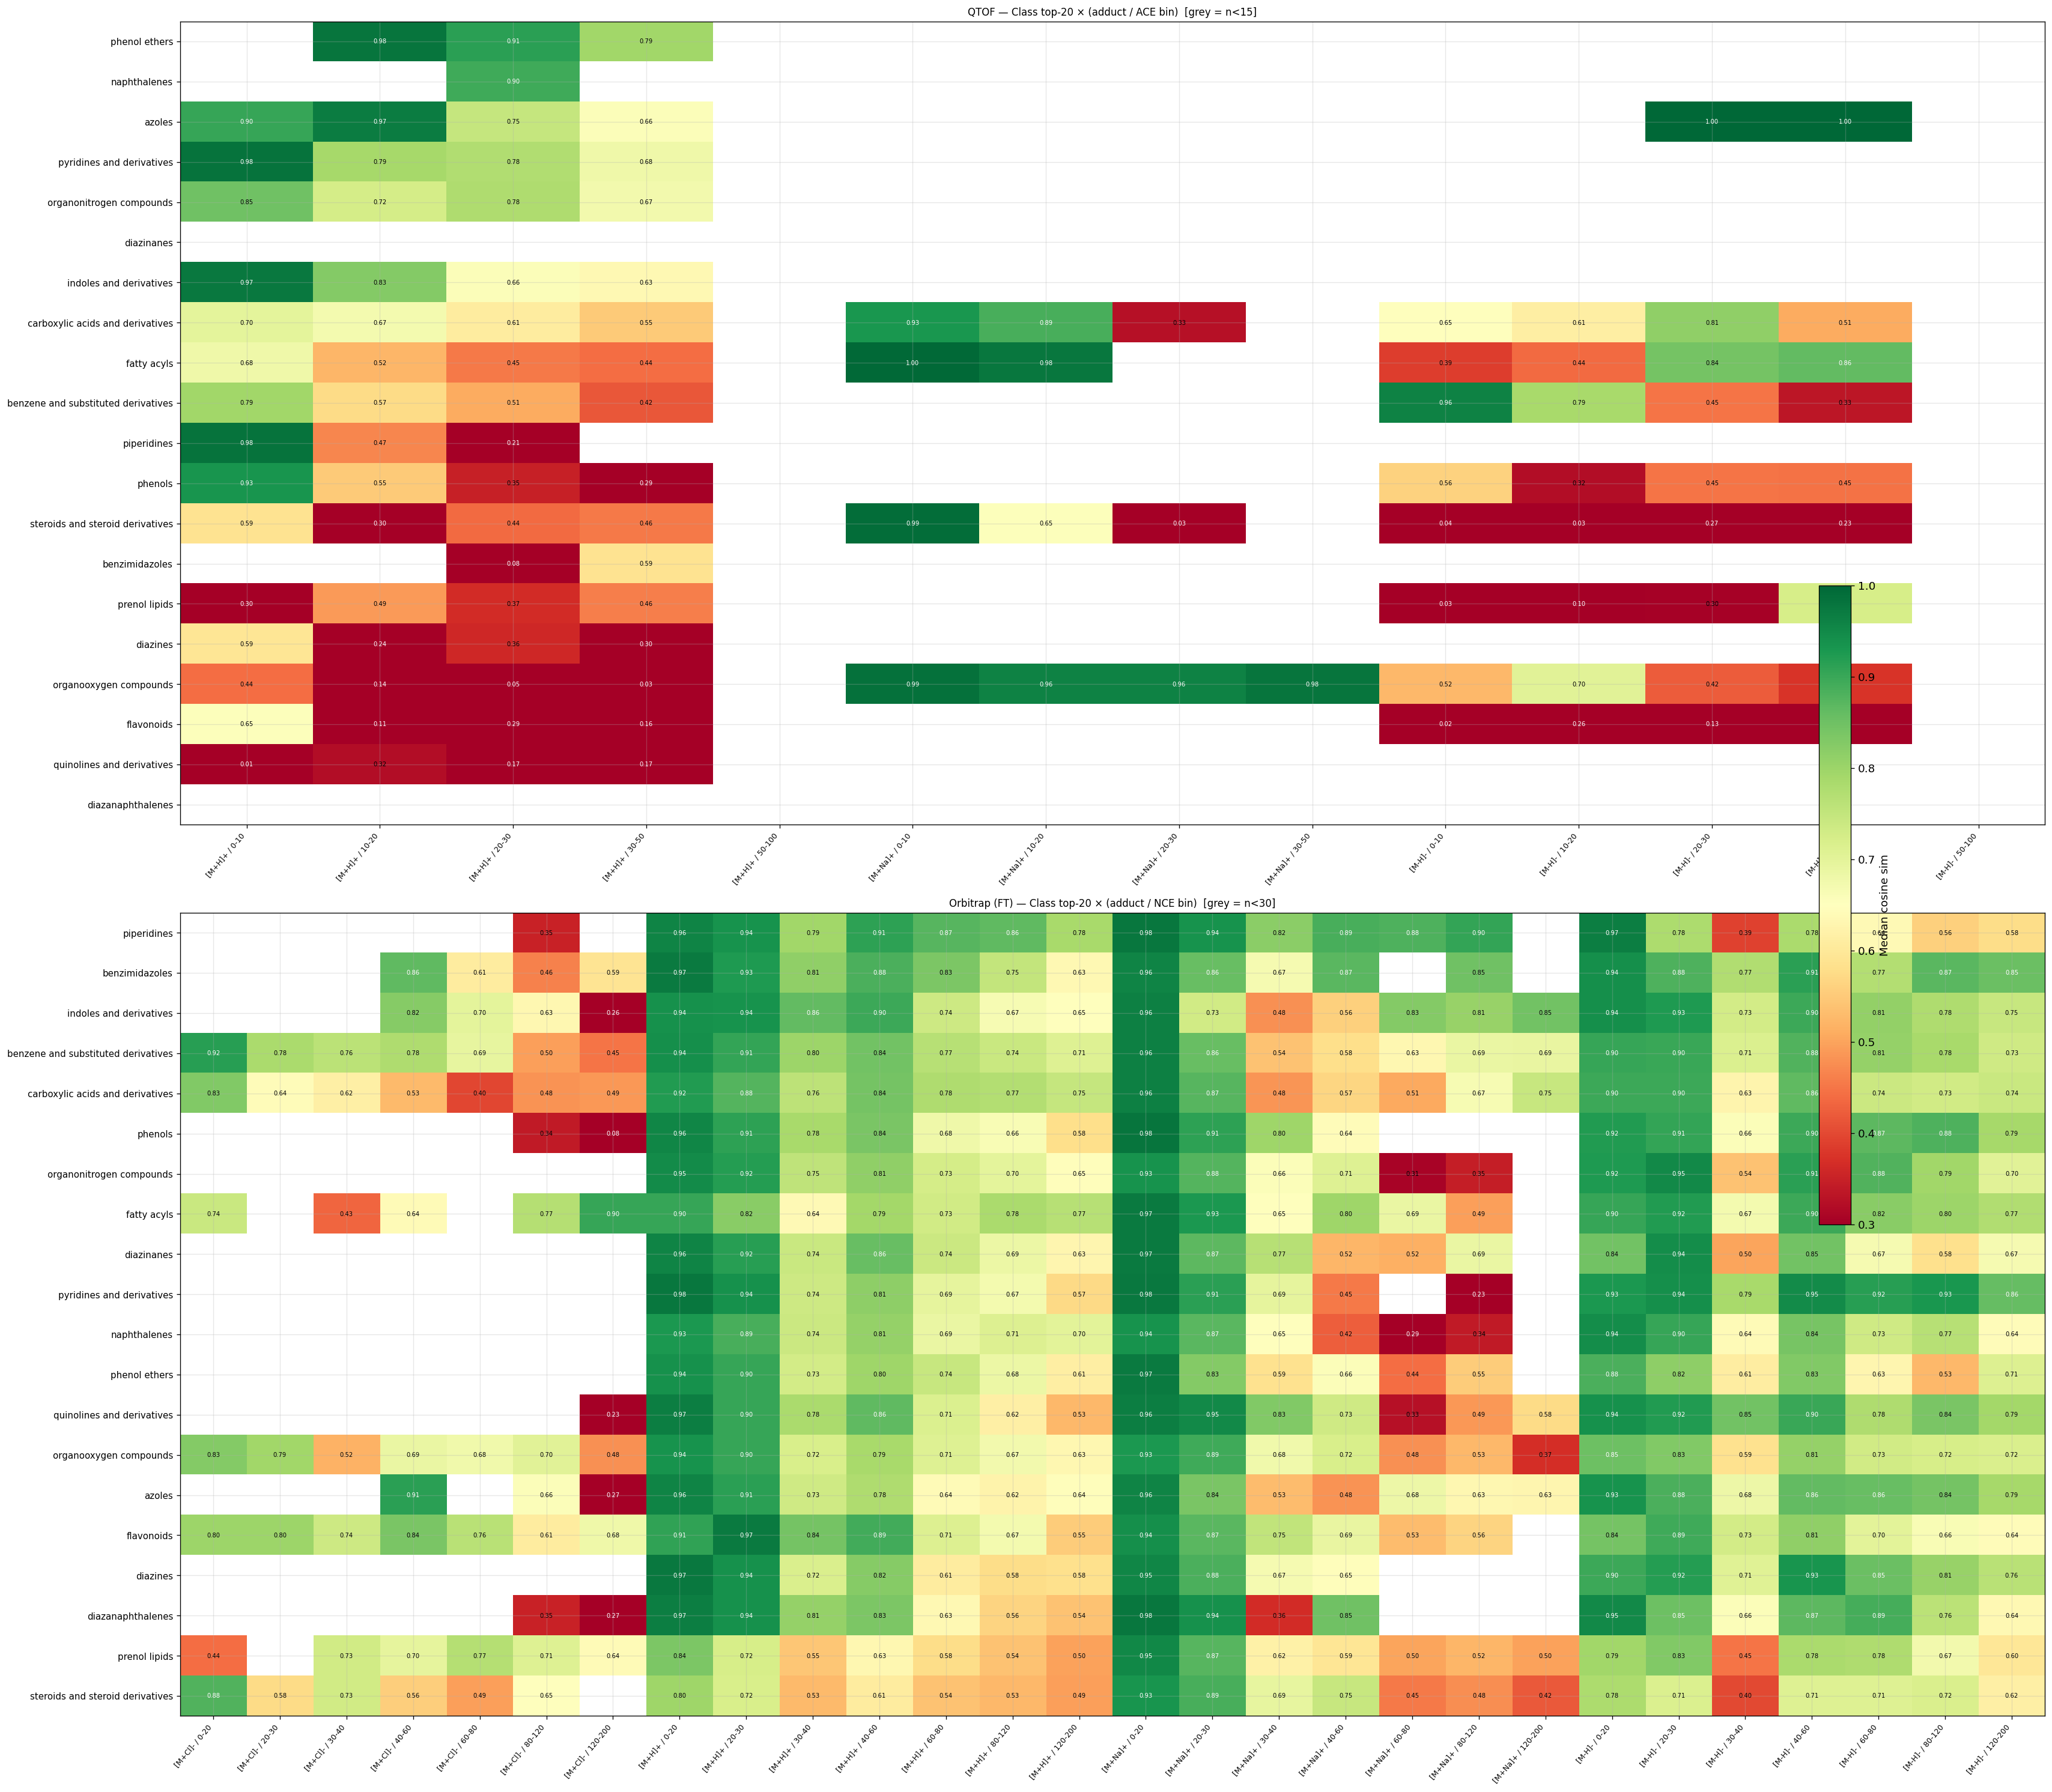

QTOF  heatmap: (20, 14)  non-null: 111
FT    heatmap: (20, 28)  non-null: 462


In [30]:
top20_klass = df["klass"].value_counts().head(20).index.tolist()
df_kl = df[df["klass"].isin(top20_klass)]

heat_kl_qt = make_cf_heatmap(df_kl, "QTOF", "klass", min_n=15)
heat_kl_ft = make_cf_heatmap(df_kl, "FT",   "klass", min_n=30)

n_cols = max(len(heat_kl_qt.columns), len(heat_kl_ft.columns))
n_rows = max(len(heat_kl_qt.index),   len(heat_kl_ft.index))

fig, axes = plt.subplots(2, 1, figsize=(n_cols * 0.95 + 2, n_rows * 1.1 + 3))
im0 = plot_heatmap(heat_kl_qt, "QTOF — Class top-20 × (adduct / ACE bin)  [grey = n<15]",  axes[0])
im1 = plot_heatmap(heat_kl_ft, "Orbitrap (FT) — Class top-20 × (adduct / NCE bin)  [grey = n<30]", axes[1])
fig.colorbar(im1, ax=axes, label="Median cosine sim", fraction=0.02, pad=0.04)
plt.tight_layout()
plt.show()

print(f"QTOF  heatmap: {heat_kl_qt.shape}  non-null: {heat_kl_qt.notna().sum().sum()}")
print(f"FT    heatmap: {heat_kl_ft.shape}  non-null: {heat_kl_ft.notna().sum().sum()}")

## 17. Summary Table

In [31]:
thresholds = [0.2, 0.5, 0.7, 0.9]

summary = {}
for t in thresholds:
    summary[f"cos_sim >= {t}"] = (df["cos_sim_0.01"] >= t).mean()

summary["mean cos_sim"] = df["cos_sim_0.01"].mean()
summary["median cos_sim"] = df["cos_sim_0.01"].median()
summary["mean cos_hun"] = df["cos_hun"].mean()
summary["median cos_hun"] = df["cos_hun"].median()
summary["n_spectra"] = len(df)
summary["n_molecules"] = df["mol_id"].nunique()

pd.Series(summary).round(4).to_frame("value")

,value
cos_sim >= 0.2,0.8787
cos_sim >= 0.5,0.7059
cos_sim >= 0.7,0.5623
cos_sim >= 0.9,0.3535
mean cos_sim,0.6704
median cos_sim,0.7714
mean cos_hun,0.6939
median cos_hun,0.7972
n_spectra,698676.0000
n_molecules,26728.0000


In [32]:
del df
gc.collect()


127545